
# Avance 6. Auditoría experimental, reproducibilidad y viabilidad técnica

## Objetivo

Este notebook reúne verificaciones adicionales realizadas durante la integración de los resultados del Proyecto Integrador con BNext. Su propósito es comprobar la reproducibilidad de las métricas reportadas, analizar limitaciones de la evaluación y documentar evidencia técnica para el artículo de difusión.

El candidato seleccionado en el Avance 5 fue R(2+1)D-18/H5, evaluado frente al baseline R3D-18. Durante la integración se identificaron diferencias entre métricas históricas y aspectos metodológicos que requerían una revisión más detallada.

## Alcance de la auditoría

Los análisis se organizan alrededor de cinco objetivos:

1. **Reproducibilidad:** verificar Average Precision (AP), diferencias entre modelos e intervalos de confianza mediante predicciones y artefactos existentes.
2. **Validez de los datos:** examinar el efecto de excluir 11 clips ambiguos de test y analizar la composición de las particiones.
3. **Precisión numérica:** investigar las discrepancias asociadas con el cálculo de softmax en FP16 y FP32.
4. **Interpretación de métricas:** contextualizar los resultados de STG-NF mediante la prevalencia de las etiquetas de RetailS.
5. **Viabilidad computacional:** caracterizar los requerimientos de inferencia de H5 como referencia para una futura evaluación de hardware Edge.

## Consideraciones metodológicas

Las pruebas son retrospectivas. Se reutilizan checkpoints, particiones, predicciones y otros artefactos de los avances anteriores. No se reentrenan modelos ni se utiliza test para seleccionar nuevos hiperparámetros o thresholds.

Las comprobaciones numéricas permiten evaluar la consistencia de resultados previamente reportados, pero no eliminan las limitaciones derivadas de la revisión dirigida de etiquetas, la inspección previa de test o la ausencia de videos operativos representativos de BNext.

Las mediciones computacionales corresponden al entorno de desarrollo y no constituyen una validación del sistema completo en hardware Edge.


In [1]:
# ============================================================
# Librerías y configuración global
# ============================================================

from pathlib import Path
import os
import sys
import random

import numpy as np
import pandas as pd

import torch
import torchvision
import sklearn


SEED = 42

# Evita entrenamientos costosos durante Restart Kernel + Run All
RUN_TRAINING = False

GENERAR_ARTEFACTOS_A5 = False

GENERAR_MODELOS_A5 = False


def fijar_semilla(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


fijar_semilla(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

In [2]:
# ============================================================
# Localización de la raíz del repositorio
# ============================================================

MARCADOR_REPOSITORIO = (
    Path("Datos")
    / "Preparacion_Datasets"
    / "avance4_split_ground_truth_v2.csv"
)


def find_repo_root():
    candidatos = []

    repo_env = os.environ.get("MNA_REPO_DIR")

    if repo_env:
        candidatos.append(Path(repo_env))

    candidatos.extend(
        [
            Path.cwd(),
            *Path.cwd().parents
        ]
    )

    for candidato in candidatos:
        if (candidato / MARCADOR_REPOSITORIO).is_file():
            return candidato.resolve()

    raise RuntimeError(
        "No se pudo localizar la raíz del repositorio. "
        "Ejecute el notebook desde el repositorio o "
        "defina la variable MNA_REPO_DIR."
    )


REPO_DIR = find_repo_root()

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

print("Repositorio localizado correctamente")

Repositorio localizado correctamente



## 1. Reproducibilidad del desempeño y su incertidumbre

### Objetivo

En el Avance 5, R(2+1)D-18/H5 obtuvo un AP superior al baseline R3D-18. Sin embargo, una diferencia puntual de desempeño no demuestra por sí sola que el candidato sea consistentemente superior.

Esta prueba busca reproducir las métricas sobre los mismos clips de test v2 y estimar la incertidumbre asociada con la diferencia de AP.

### Procedimiento

Se recuperan las predicciones almacenadas de ambos modelos y se emparejan mediante `clip_id`, verificando que correspondan a los mismos 136 clips y que sus etiquetas coincidan.

Se calcula Average Precision (AP) para cada modelo y su diferencia:

**ΔAP = AP(H5) − AP(baseline)**

Posteriormente, se aplica bootstrap pareado con 2,000 remuestreos de grupos experimentales, utilizando la semilla 42.

El remuestreo se realiza por grupo, en lugar de por clip individual, para considerar parcialmente la dependencia entre fragmentos relacionados. En cada réplica se evalúan ambos modelos sobre la misma muestra y se obtiene un intervalo de confianza del 95 %.

### Interpretación esperada

Los resultados permiten verificar:

- El AP individual de cada modelo.
- La diferencia puntual de AP.
- La amplitud de los intervalos de confianza.
- Si el intervalo de la diferencia incluye cero.

### Limitaciones

El bootstrap por grupos no elimina los problemas de representatividad del dataset ni la incertidumbre causada por el reducido número de grupos y eventos positivos.

Además, test había sido inspeccionado durante el desarrollo y posteriormente se excluyeron 11 casos ambiguos mediante una revisión dirigida por errores del baseline. Por ello, esta auditoría verifica reproducibilidad numérica y cuantifica incertidumbre, pero no constituye una evaluación confirmatoria completamente independiente.

Los resultados no se utilizan para modificar checkpoints ni thresholds.


In [3]:
import numpy as np
import pandas as pd

from sklearn.metrics import average_precision_score

SEED = 42
N_BOOTSTRAP = 2000

baseline_path = (
    REPO_DIR
    / "Notebooks"
    / "checkpoints"
    / "r3d18_baseline_test_predictions.csv"
)

final_path = (
    REPO_DIR
    / "Datos"
    / "Preparacion_Datasets"
    / "avance5_artefactos"
    / "predicciones_r2plus1d_h5_test.csv"
)

df_baseline = pd.read_csv(baseline_path)
df_final = pd.read_csv(final_path)

# Conservar exactamente los clips presentes en test v2.
df_pareado = (
    df_final[
        [
            "clip_id",
            "grupo_experimental",
            "label",
            "p_r2plus1d_h5"
        ]
    ]
    .merge(
        df_baseline[
            [
                "clip_id",
                "clase_binaria",
                "p_ocultamiento"
            ]
        ],
        on="clip_id",
        how="inner",
        validate="one_to_one"
    )
)

assert len(df_pareado) == 136

assert np.array_equal(
    df_pareado["label"].to_numpy(),
    df_pareado["clase_binaria"].to_numpy()
)

y = df_pareado["label"].to_numpy(dtype=int)

p_baseline = df_pareado[
    "p_ocultamiento"
].to_numpy(dtype=float)

p_final = df_pareado[
    "p_r2plus1d_h5"
].to_numpy(dtype=float)

grupos = df_pareado[
    "grupo_experimental"
].astype(str).to_numpy()

grupos_unicos = np.unique(grupos)

ap_baseline_obs = average_precision_score(
    y,
    p_baseline
)

ap_final_obs = average_precision_score(
    y,
    p_final
)

delta_obs = ap_final_obs - ap_baseline_obs

rng = np.random.default_rng(SEED)

bootstrap_baseline = []
bootstrap_final = []
bootstrap_delta = []

for _ in range(N_BOOTSTRAP):

    muestra_grupos = rng.choice(
        grupos_unicos,
        size=len(grupos_unicos),
        replace=True
    )

    indices = np.concatenate([
        np.where(grupos == grupo)[0]
        for grupo in muestra_grupos
    ])

    y_b = y[indices]

    if y_b.sum() == 0:
        continue

    ap_b = average_precision_score(
        y_b,
        p_baseline[indices]
    )

    ap_f = average_precision_score(
        y_b,
        p_final[indices]
    )

    bootstrap_baseline.append(ap_b)
    bootstrap_final.append(ap_f)
    bootstrap_delta.append(ap_f - ap_b)

ic_baseline = np.percentile(
    bootstrap_baseline,
    [2.5, 97.5]
)

ic_final = np.percentile(
    bootstrap_final,
    [2.5, 97.5]
)

ic_delta = np.percentile(
    bootstrap_delta,
    [2.5, 97.5]
)

print("AP baseline:", round(ap_baseline_obs, 4))
print("IC 95% baseline:", np.round(ic_baseline, 4))

print("AP final:", round(ap_final_obs, 4))
print("IC 95% final:", np.round(ic_final, 4))

print("Delta AP:", round(delta_obs, 4))
print("IC 95% delta:", np.round(ic_delta, 4))

AP baseline: 0.6067
IC 95% baseline: [0.4224 0.9487]
AP final: 0.8041
IC 95% final: [0.3734 0.965 ]
Delta AP: 0.1974
IC 95% delta: [-0.1143  0.228 ]



## 2. Análisis de sensibilidad del ground truth

### Objetivo

Durante el Avance 4 se excluyeron 11 clips positivos de test v1 porque la evidencia visual de ocultamiento era ambigua. Los 11 casos habían sido identificados como falsos negativos del baseline R3D-18.

Esta decisión modificó la composición de test:

| Indicador | Test v1 | Test v2 |
|---|---:|---:|
| Clips | 147 | 136 |
| Positivos | 28 | 17 |
| Negativos | 119 | 119 |

El objetivo de este análisis es determinar cuánto cambian las métricas del baseline y del candidato R(2+1)D-18/H5 al evaluar ambos modelos sobre las dos versiones del conjunto de prueba.

### Procedimiento

Primero se reconstruye el modelo H5 utilizando su checkpoint original y las funciones de preprocesamiento e inferencia necesarias. Esto permite ejecutar la auditoría sin depender del estado del kernel del Avance 5.

Posteriormente:

1. Se recuperan los 11 clips excluidos: cuatro de DCSASS y siete de MNNIT.
2. Se obtiene el score de H5 para estos clips, sin reentrenar el modelo.
3. Se reconstruyen las predicciones sobre los 147 clips de test v1.
4. Se comparan ambos modelos sobre test v1 y test v2, conservando sus thresholds experimentales.
5. Se calcula un bootstrap pareado por grupo para estimar la incertidumbre de la diferencia de AP.

### Interpretación

La comparación permite distinguir los cambios ocasionados por la composición del conjunto de evaluación de los cambios atribuibles al entrenamiento.

Los resultados reproducidos fueron:

| Indicador | Test v1 | Test v2 |
|---|---:|---:|
| AP baseline | 0.5393 | 0.6067 |
| AP H5 | 0.7459 | 0.8041 |
| Diferencia de AP | +0.2067 | +0.1974 |

Ambos modelos aumentaron su AP después de la exclusión, aun cuando sus checkpoints permanecieron sin cambios. La diferencia puntual a favor de H5 persistió, pero los intervalos bootstrap de la diferencia incluyeron cero.

### Limitación metodológica

La revisión de etiquetas estuvo dirigida por los errores del baseline. Por tanto, la exclusión de casos no fue ciega ni simétrica entre clases o modelos.

El análisis permite cuantificar la sensibilidad de los resultados a esta decisión, pero no elimina el posible sesgo introducido durante la revisión de test. Los resultados deben interpretarse como evidencia retrospectiva, no como una evaluación confirmatoria independiente.


In [4]:
# ============================================================
# A6 - Dependencias autocontenidas para inferencia RGB
#
# Esta celda permite ejecutar Avance 6 sin haber ejecutado
# Avance 5 en el mismo kernel.
#
# Se reutilizan únicamente artefactos congelados del proyecto:
# - checkpoint R(2+1)D-18/H5
# - predicciones finales de test v2
# - dataset/split persistido
#
# No se entrena ningún modelo.
# ============================================================

from pathlib import Path
import os
import cv2

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision.models import video as video_models


# ------------------------------------------------------------
# 1. Dispositivo
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Dispositivo A6:", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ------------------------------------------------------------
# 2. Artefactos congelados utilizados por A6
# ------------------------------------------------------------

CHECKPOINT_R2PLUS1D_H5_PATH = (
    REPO_DIR
    / "Notebooks"
    / "checkpoints"
    / "r2plus1d_18_avance4_h5.pt"
)

ARTEFACTOS_A5_DIR = (
    REPO_DIR
    / "Datos"
    / "Preparacion_Datasets"
    / "avance5_artefactos"
)

PREDICCIONES_R2_TEST_PATH = (
    ARTEFACTOS_A5_DIR
    / "predicciones_r2plus1d_h5_test.csv"
)

THRESHOLD_R2PLUS1D_H5 = 0.99690056


artefactos_requeridos = {
    "checkpoint R(2+1)D-18/H5":
        CHECKPOINT_R2PLUS1D_H5_PATH,

    "predicciones R(2+1)D-18/H5 test v2":
        PREDICCIONES_R2_TEST_PATH,
}


for nombre, ruta in artefactos_requeridos.items():

    if not ruta.is_file():
        raise FileNotFoundError(
            f"No se encontró {nombre}: {ruta}"
        )

    print(
        f"{nombre}: OK"
    )


print(
    "Threshold congelado R(2+1)D-18/H5:",
    THRESHOLD_R2PLUS1D_H5
)


# ------------------------------------------------------------
# 3. Configuración de clips
# ------------------------------------------------------------

NUM_FRAMES = 16
BATCH_INFERENCIA_A6 = 16


def cargar_frames_rgb(
    video_path,
    num_frames=NUM_FRAMES
):
    """
    Lee num_frames distribuidos uniformemente entre
    el primer y último frame del clip.

    Reproduce la preparación utilizada en los avances
    experimentales previos.
    """

    cap = cv2.VideoCapture(
        str(video_path)
    )

    if not cap.isOpened():
        raise RuntimeError(
            "No se pudo abrir el clip: "
            f"{video_path.name}"
        )

    n_frames = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )

    if n_frames < num_frames:

        cap.release()

        raise RuntimeError(
            f"El clip {video_path.name} "
            f"contiene {n_frames} frames "
            f"y requiere al menos "
            f"{num_frames}."
        )

    indices = np.round(
        np.linspace(
            0,
            n_frames - 1,
            num_frames
        )
    ).astype(int)

    frames = []

    for idx in indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(idx)
        )

        ret, frame = cap.read()

        if not ret:

            cap.release()

            raise RuntimeError(
                "No se pudo leer el frame "
                f"{idx} del clip "
                f"{video_path.name}"
            )

        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frames.append(
            torch
            .from_numpy(
                frame.copy()
            )
            .permute(
                2,
                0,
                1
            )
        )

    cap.release()

    return torch.stack(
        frames,
        dim=0
    )


# ------------------------------------------------------------
# 4. Dataset RGB local de A6
# ------------------------------------------------------------

class VideoDatasetRGB(Dataset):

    def __init__(
        self,
        dataframe,
        clips_dir,
        transform
    ):
        self.df = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.clips_dir = Path(
            clips_dir
        )

        self.transform = transform


    def __len__(self):
        return len(self.df)


    def __getitem__(self, idx):

        fila = self.df.iloc[idx]

        video_path = (
            self.clips_dir
            / fila["nombre_clip"]
        )

        if not video_path.exists():

            raise FileNotFoundError(
                "No se encontró el clip "
                f"requerido: "
                f"{video_path.name}"
            )

        clip = cargar_frames_rgb(
            video_path
        )

        if self.transform is not None:

            clip = self.transform(
                clip
            )

        etiqueta = torch.tensor(
            int(
                fila["clase_binaria"]
            ),
            dtype=torch.long
        )

        return clip, etiqueta


# ------------------------------------------------------------
# 5. Inferencia local
# ------------------------------------------------------------

@torch.inference_mode()
def inferir_probabilidades_rgb(
    modelo,
    loader,
    device,
    usar_amp=True
):
    """
    Ejecuta inferencia binaria y devuelve:
      y_true : etiquetas enteras
      y_prob : P(clase=ocultamiento)

    Implementación local para que A6 no dependa
    de Scripts.artefactos_avance5.
    """

    modelo.eval()

    etiquetas = []
    probabilidades = []

    amp_activo = (
        usar_amp
        and device.type == "cuda"
    )

    for clips, labels in loader:

        clips = clips.to(
            device,
            non_blocking=True
        )

        if amp_activo:

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                logits = modelo(
                    clips
                )

        else:

            logits = modelo(
                clips
            )

        probs = torch.softmax(
            logits,
            dim=1
        )[:, 1]

        etiquetas.append(
            labels
            .detach()
            .cpu()
            .numpy()
        )

        probabilidades.append(
            probs
            .detach()
            .float()
            .cpu()
            .numpy()
        )

    y_true = np.concatenate(
        etiquetas
    ).astype(
        np.int64
    )

    y_prob = np.concatenate(
        probabilidades
    ).astype(
        np.float64
    )

    if not np.isfinite(
        y_prob
    ).all():

        raise RuntimeError(
            "La inferencia produjo "
            "probabilidades no finitas."
        )

    return {
        "y_true": y_true,
        "y_prob": y_prob
    }


print(
    "Dependencias autocontenidas "
    "de inferencia A6: OK"
)

Dispositivo A6: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
checkpoint R(2+1)D-18/H5: OK
predicciones R(2+1)D-18/H5 test v2: OK
Threshold congelado R(2+1)D-18/H5: 0.99690056
Dependencias autocontenidas de inferencia A6: OK


In [5]:
# ============================================================
# A6 - ANÁLISIS DE SENSIBILIDAD DEL GROUND TRUTH
# Test v1 original (147 clips) vs test v2 (136 clips)
#
# Objetivo:
# 1. Puntuar R(2+1)D-18/H5 sobre los 11 positivos ambiguos
#    retirados de test v2.
# 2. Reconstruir las predicciones del candidato sobre test v1.
# 3. Comparar baseline y candidato sobre exactamente los
#    mismos 147 clips.
# 4. Calcular bootstrap pareado por grupo para Delta AP.
#
# No se reentrena ningún modelo.
# No se modifica ningún threshold.
# ============================================================

from pathlib import Path
import os

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision.models import video as video_models

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


# ------------------------------------------------------------
# 1. Validaciones previas
# ------------------------------------------------------------

variables_requeridas = [
    "REPO_DIR",
    "DEVICE",
    "CHECKPOINT_R2PLUS1D_H5_PATH",
    "PREDICCIONES_R2_TEST_PATH",
    "THRESHOLD_R2PLUS1D_H5",
    "VideoDatasetRGB",
    "inferir_probabilidades_rgb",
]

faltantes = [
    nombre
    for nombre in variables_requeridas
    if nombre not in globals()
]

if faltantes:
    raise RuntimeError(
        "Ejecute primero las celdas de configuración "
        "de Avance 6. "
        f"Variables faltantes: {faltantes}"
    )

AMBIGUOUS_TEST_CLIPS_A6 = [
    # DCSASS
    "Shoplifting006_x264_28",
    "Shoplifting006_x264_29",
    "Shoplifting006_x264_19",
    "Shoplifting021_x264_23",

    # MNNIT
    "MNNIT_065",
    "MNNIT_067",
    "MNNIT_013",
    "MNNIT_064",
    "MNNIT_069",
    "MNNIT_066",
    "MNNIT_068",
]

THRESHOLD_BASELINE = 0.7090
THRESHOLD_CANDIDATO = float(THRESHOLD_R2PLUS1D_H5)

assert np.isclose(
    THRESHOLD_CANDIDATO,
    0.99690056,
    atol=1e-6
)


# ------------------------------------------------------------
# 2. Recuperar test v1 original y predicciones del baseline
# ------------------------------------------------------------

SPLIT_V2_PATH = (
    REPO_DIR
    / "Datos"
    / "Preparacion_Datasets"
    / "avance4_split_ground_truth_v2.csv"
)

BASELINE_PRED_PATH = (
    REPO_DIR
    / "Notebooks"
    / "checkpoints"
    / "r3d18_baseline_test_predictions.csv"
)

if not SPLIT_V2_PATH.is_file():
    raise FileNotFoundError(SPLIT_V2_PATH)

if not BASELINE_PRED_PATH.is_file():
    raise FileNotFoundError(BASELINE_PRED_PATH)


df_split_completo = pd.read_csv(SPLIT_V2_PATH)

# El archivo v2 conserva los 985 registros originales;
# los ambiguos están marcados como no elegibles.
df_test_v1_meta = (
    df_split_completo[
        df_split_completo["split"].eq("test")
    ]
    .copy()
    .reset_index(drop=True)
)

df_baseline_v1 = pd.read_csv(BASELINE_PRED_PATH)


assert len(df_test_v1_meta) == 147
assert int(df_test_v1_meta["clase_binaria"].sum()) == 28

assert len(df_baseline_v1) == 147
assert int(df_baseline_v1["clase_binaria"].sum()) == 28


# ------------------------------------------------------------
# 3. Extraer los 11 clips ambiguos
# ------------------------------------------------------------

df_ambiguos = (
    df_test_v1_meta[
        df_test_v1_meta["clip_id"].isin(
            AMBIGUOUS_TEST_CLIPS_A6
        )
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(df_ambiguos) == 11
assert df_ambiguos["clase_binaria"].eq(1).all()


print("=== CLIPS AMBIGUOS ===")
print("Total:", len(df_ambiguos))
print(
    df_ambiguos["dataset"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 4. Preparar solamente los 11 clips para R(2+1)D-18/H5
# ------------------------------------------------------------

ruta_clips = os.environ.get("BNEXT_CLIPS_DIR")

if not ruta_clips:
    raise RuntimeError(
        "BNEXT_CLIPS_DIR no está configurada."
    )

CLIPS_DIR_A6 = Path(ruta_clips)

if not CLIPS_DIR_A6.is_dir():
    raise RuntimeError(
        "BNEXT_CLIPS_DIR no apunta a un directorio válido."
    )


transform_a6 = (
    video_models
    .R2Plus1D_18_Weights
    .DEFAULT
    .transforms()
)

dataset_ambiguos = VideoDatasetRGB(
    df_ambiguos,
    CLIPS_DIR_A6,
    transform_a6
)

loader_ambiguos = DataLoader(
    dataset_ambiguos,
    batch_size=11,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)


# ------------------------------------------------------------
# 5. Cargar exactamente el checkpoint H5 actual
# ------------------------------------------------------------

checkpoint_a6 = torch.load(
    CHECKPOINT_R2PLUS1D_H5_PATH,
    map_location="cpu",
    weights_only=False
)

modelo_a6 = video_models.r2plus1d_18(
    weights=None
)

modelo_a6.fc = nn.Linear(
    modelo_a6.fc.in_features,
    2
)

modelo_a6.load_state_dict(
    checkpoint_a6["model_state_dict"]
)

modelo_a6 = (
    modelo_a6
    .to(DEVICE)
    .eval()
)


# ------------------------------------------------------------
# 6. Inferir los 11 ambiguos
# ------------------------------------------------------------

resultado_ambiguos = (
    inferir_probabilidades_rgb(
        modelo_a6,
        loader_ambiguos,
        DEVICE,
        usar_amp=True
    )
)

assert np.array_equal(
    resultado_ambiguos["y_true"],
    df_ambiguos["clase_binaria"].to_numpy(dtype=np.int64)
)

df_pred_ambiguos = df_ambiguos[
    [
        "dataset",
        "video_id",
        "clip_id",
        "grupo_experimental",
        "clase_binaria",
    ]
].copy()

df_pred_ambiguos["p_r2plus1d_h5"] = (
    resultado_ambiguos["y_prob"]
)

df_pred_ambiguos["pred_r2plus1d_h5"] = (
    df_pred_ambiguos["p_r2plus1d_h5"]
    >= THRESHOLD_CANDIDATO
).astype(int)


# ------------------------------------------------------------
# 7. Añadir la probabilidad histórica del baseline
# ------------------------------------------------------------

df_pred_ambiguos = df_pred_ambiguos.merge(
    df_baseline_v1[
        [
            "clip_id",
            "p_ocultamiento",
        ]
    ],
    on="clip_id",
    how="left",
    validate="one_to_one"
)

df_pred_ambiguos = df_pred_ambiguos.rename(
    columns={
        "p_ocultamiento": "p_r3d18_baseline"
    }
)


# ------------------------------------------------------------
# 8. Cargar las 136 predicciones actuales del candidato en v2
# ------------------------------------------------------------

if not PREDICCIONES_R2_TEST_PATH.is_file():
    raise FileNotFoundError(
        PREDICCIONES_R2_TEST_PATH
    )

df_r2_v2 = pd.read_csv(
    PREDICCIONES_R2_TEST_PATH
)

assert len(df_r2_v2) == 136


# ------------------------------------------------------------
# 9. Reconstruir candidato sobre test v1 = 136 + 11
# ------------------------------------------------------------

df_r2_v1 = pd.concat(
    [
        df_r2_v2[
            [
                "clip_id",
                "p_r2plus1d_h5",
            ]
        ],
        df_pred_ambiguos[
            [
                "clip_id",
                "p_r2plus1d_h5",
            ]
        ],
    ],
    ignore_index=True
)

assert len(df_r2_v1) == 147
assert df_r2_v1["clip_id"].nunique() == 147


# ------------------------------------------------------------
# 10. Construir tabla pareada completa de test v1
# ------------------------------------------------------------

df_pareado_v1 = (
    df_test_v1_meta[
        [
            "dataset",
            "video_id",
            "clip_id",
            "grupo_experimental",
            "clase_binaria",
        ]
    ]
    .merge(
        df_baseline_v1[
            [
                "clip_id",
                "p_ocultamiento",
            ]
        ],
        on="clip_id",
        how="inner",
        validate="one_to_one"
    )
    .merge(
        df_r2_v1,
        on="clip_id",
        how="inner",
        validate="one_to_one"
    )
)

assert len(df_pareado_v1) == 147

assert int(
    df_pareado_v1["clase_binaria"].sum()
) == 28


# ------------------------------------------------------------
# 11. Función de métricas dependientes e independientes
# ------------------------------------------------------------

def metricas_sensibilidad(
    y_true,
    y_prob,
    threshold
):
    y_true = np.asarray(y_true, dtype=int)
    y_prob = np.asarray(y_prob, dtype=float)

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "AP": average_precision_score(
            y_true,
            y_prob
        ),
        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "specificity": (
            tn / (tn + fp)
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }


y_v1 = df_pareado_v1[
    "clase_binaria"
].to_numpy(dtype=int)

p_baseline_v1 = df_pareado_v1[
    "p_ocultamiento"
].to_numpy(dtype=float)

p_candidato_v1 = df_pareado_v1[
    "p_r2plus1d_h5"
].to_numpy(dtype=float)


m_baseline_v1 = metricas_sensibilidad(
    y_v1,
    p_baseline_v1,
    THRESHOLD_BASELINE
)

m_candidato_v1 = metricas_sensibilidad(
    y_v1,
    p_candidato_v1,
    THRESHOLD_CANDIDATO
)


# Control: baseline debe reproducir Avance 3
assert np.isclose(
    m_baseline_v1["AP"],
    0.5393,
    atol=5e-5
)


# ------------------------------------------------------------
# 12. Reconstruir también v2 con los mismos vectores
# ------------------------------------------------------------

mask_v2 = ~df_pareado_v1[
    "clip_id"
].isin(
    AMBIGUOUS_TEST_CLIPS_A6
)

df_pareado_v2 = (
    df_pareado_v1[
        mask_v2
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(df_pareado_v2) == 136
assert int(
    df_pareado_v2["clase_binaria"].sum()
) == 17


m_baseline_v2 = metricas_sensibilidad(
    df_pareado_v2["clase_binaria"],
    df_pareado_v2["p_ocultamiento"],
    THRESHOLD_BASELINE
)

m_candidato_v2 = metricas_sensibilidad(
    df_pareado_v2["clase_binaria"],
    df_pareado_v2["p_r2plus1d_h5"],
    THRESHOLD_CANDIDATO
)


assert np.isclose(
    m_baseline_v2["AP"],
    0.6067,
    atol=5e-5
)

assert np.isclose(
    m_candidato_v2["AP"],
    0.8041,
    atol=5e-5
)


# ------------------------------------------------------------
# 13. Comparación v1 vs v2
# ------------------------------------------------------------

tabla_sensibilidad = pd.DataFrame([
    {
        "test": "v1 original",
        "modelo": "R3D-18 baseline",
        **m_baseline_v1
    },
    {
        "test": "v1 original",
        "modelo": "R(2+1)D-18/H5",
        **m_candidato_v1
    },
    {
        "test": "v2 depurado",
        "modelo": "R3D-18 baseline",
        **m_baseline_v2
    },
    {
        "test": "v2 depurado",
        "modelo": "R(2+1)D-18/H5",
        **m_candidato_v2
    },
])


display(
    tabla_sensibilidad.style.format({
        "AP": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "F1": "{:.4f}",
        "specificity": "{:.4f}",
    })
)


# ------------------------------------------------------------
# 14. Efecto puntual de la auditoría
# ------------------------------------------------------------

delta_ap_v1 = (
    m_candidato_v1["AP"]
    - m_baseline_v1["AP"]
)

delta_ap_v2 = (
    m_candidato_v2["AP"]
    - m_baseline_v2["AP"]
)

n_detectados_ambiguos = int(
    df_pred_ambiguos[
        "pred_r2plus1d_h5"
    ].sum()
)


print("\n=== RESULTADOS PRINCIPALES ===")

print(
    "Ambiguos detectados por R2/H5:",
    f"{n_detectados_ambiguos}/11"
)

print(
    "AP baseline test v1:",
    round(m_baseline_v1["AP"], 4)
)

print(
    "AP candidato test v1:",
    round(m_candidato_v1["AP"], 4)
)

print(
    "Delta AP test v1:",
    round(delta_ap_v1, 4)
)

print(
    "AP baseline test v2:",
    round(m_baseline_v2["AP"], 4)
)

print(
    "AP candidato test v2:",
    round(m_candidato_v2["AP"], 4)
)

print(
    "Delta AP test v2:",
    round(delta_ap_v2, 4)
)


print("\n=== 11 CLIPS AMBIGUOS ===")

display(
    df_pred_ambiguos[
        [
            "dataset",
            "clip_id",
            "grupo_experimental",
            "p_r3d18_baseline",
            "p_r2plus1d_h5",
            "pred_r2plus1d_h5",
        ]
    ]
    .sort_values(
        "p_r2plus1d_h5",
        ascending=False
    )
    .style.format({
        "p_r3d18_baseline": "{:.6f}",
        "p_r2plus1d_h5": "{:.6f}",
    })
)


# ------------------------------------------------------------
# 15. Bootstrap pareado por grupo
# ------------------------------------------------------------

def bootstrap_delta_ap_por_grupo(
    df,
    n_bootstrap=2000,
    seed=42
):
    rng = np.random.default_rng(seed)

    grupos = (
        df["grupo_experimental"]
        .astype(str)
        .to_numpy()
    )

    grupos_unicos = np.unique(grupos)

    y = df[
        "clase_binaria"
    ].to_numpy(dtype=int)

    p_b = df[
        "p_ocultamiento"
    ].to_numpy(dtype=float)

    p_c = df[
        "p_r2plus1d_h5"
    ].to_numpy(dtype=float)

    delta_boot = []
    ap_b_boot = []
    ap_c_boot = []

    n_sin_positivos = 0

    for _ in range(n_bootstrap):

        muestra_grupos = rng.choice(
            grupos_unicos,
            size=len(grupos_unicos),
            replace=True
        )

        indices = np.concatenate([
            np.where(
                grupos == grupo
            )[0]
            for grupo in muestra_grupos
        ])

        y_b = y[indices]

        if y_b.sum() == 0:
            n_sin_positivos += 1
            continue

        ap_b = average_precision_score(
            y_b,
            p_b[indices]
        )

        ap_c = average_precision_score(
            y_b,
            p_c[indices]
        )

        ap_b_boot.append(ap_b)
        ap_c_boot.append(ap_c)
        delta_boot.append(
            ap_c - ap_b
        )

    return {
        "n_total": n_bootstrap,
        "n_validos": len(delta_boot),
        "n_sin_positivos": n_sin_positivos,
        "ic_baseline": np.percentile(
            ap_b_boot,
            [2.5, 97.5]
        ),
        "ic_candidato": np.percentile(
            ap_c_boot,
            [2.5, 97.5]
        ),
        "ic_delta": np.percentile(
            delta_boot,
            [2.5, 97.5]
        ),
    }


bootstrap_v1 = bootstrap_delta_ap_por_grupo(
    df_pareado_v1,
    n_bootstrap=2000,
    seed=42
)

bootstrap_v2 = bootstrap_delta_ap_por_grupo(
    df_pareado_v2,
    n_bootstrap=2000,
    seed=42
)


print("\n=== BOOTSTRAP PAREADO TEST V1 ===")
print(
    "Réplicas válidas:",
    bootstrap_v1["n_validos"],
    "/",
    bootstrap_v1["n_total"]
)
print(
    "Réplicas sin positivos:",
    bootstrap_v1["n_sin_positivos"]
)
print(
    "IC95% AP baseline:",
    np.round(
        bootstrap_v1["ic_baseline"],
        4
    )
)
print(
    "IC95% AP candidato:",
    np.round(
        bootstrap_v1["ic_candidato"],
        4
    )
)
print(
    "IC95% Delta AP:",
    np.round(
        bootstrap_v1["ic_delta"],
        4
    )
)


print("\n=== CONTROL BOOTSTRAP TEST V2 ===")
print(
    "IC95% Delta AP:",
    np.round(
        bootstrap_v2["ic_delta"],
        4
    )
)


# ------------------------------------------------------------
# 16. Guardar evidencia reproducible para Avance 6
# ------------------------------------------------------------

SALIDA_DIR = (
    REPO_DIR
    / "Datos"
    / "Preparacion_Datasets"
    / "avance6_artefactos"
)

print(
    "Artefactos A6:",
    SALIDA_DIR.relative_to(
        REPO_DIR
    )
)

SALIDA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Artefactos A6:",
    SALIDA_DIR.relative_to(
        REPO_DIR
    )
)

SALIDA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

tabla_sensibilidad.to_csv(
    SALIDA_DIR
    / "sensibilidad_ground_truth_test_v1_v2.csv",
    index=False
)

df_pred_ambiguos.to_csv(
    SALIDA_DIR
    / "sensibilidad_11_ambiguos_r2plus1d_h5.csv",
    index=False
)

pd.DataFrame([
    {
        "dataset": "test_v1",
        "delta_ap": delta_ap_v1,
        "bootstrap_validos": bootstrap_v1["n_validos"],
        "bootstrap_sin_positivos": bootstrap_v1["n_sin_positivos"],
        "ic_delta_inf": bootstrap_v1["ic_delta"][0],
        "ic_delta_sup": bootstrap_v1["ic_delta"][1],
    },
    {
        "dataset": "test_v2",
        "delta_ap": delta_ap_v2,
        "bootstrap_validos": bootstrap_v2["n_validos"],
        "bootstrap_sin_positivos": bootstrap_v2["n_sin_positivos"],
        "ic_delta_inf": bootstrap_v2["ic_delta"][0],
        "ic_delta_sup": bootstrap_v2["ic_delta"][1],
    }
]).to_csv(
    SALIDA_DIR
    / "sensibilidad_ground_truth_bootstrap.csv",
    index=False
)


# Liberar memoria GPU
del modelo_a6
del checkpoint_a6

if torch.cuda.is_available():
    torch.cuda.empty_cache()

=== CLIPS AMBIGUOS ===
Total: 11
dataset
DCSASS    4
MNNIT     7
Name: count, dtype: int64


,test,modelo,AP,precision,recall,F1,specificity,TN,FP,FN,TP
0,v1 original,R3D-18 baseline,0.5393,0.5769,0.5357,0.5556,0.9076,108,11,13,15
1,v1 original,R(2+1)D-18/H5,0.7459,0.8125,0.4643,0.5909,0.9748,116,3,15,13
2,v2 depurado,R3D-18 baseline,0.6067,0.5769,0.8824,0.6977,0.9076,108,11,2,15
3,v2 depurado,R(2+1)D-18/H5,0.8041,0.7857,0.6471,0.7097,0.9748,116,3,6,11



=== RESULTADOS PRINCIPALES ===
Ambiguos detectados por R2/H5: 2/11
AP baseline test v1: 0.5393
AP candidato test v1: 0.7459
Delta AP test v1: 0.2067
AP baseline test v2: 0.6067
AP candidato test v2: 0.8041
Delta AP test v2: 0.1974

=== 11 CLIPS AMBIGUOS ===


,dataset,clip_id,grupo_experimental,p_r3d18_baseline,p_r2plus1d_h5,pred_r2plus1d_h5
5,MNNIT,MNNIT_064,G039,0.384000,0.999512,1
4,MNNIT,MNNIT_013,G039,0.371000,0.999023,1
6,MNNIT,MNNIT_065,G039,0.160900,0.995605,0
8,MNNIT,MNNIT_067,G039,0.334000,0.990234,0
9,MNNIT,MNNIT_068,G039,0.615700,0.987793,0
7,MNNIT,MNNIT_066,G039,0.439200,0.982910,0
10,MNNIT,MNNIT_069,G039,0.414800,0.978027,0
3,DCSASS,Shoplifting021_x264_23,G014,0.009450,0.694824,0
1,DCSASS,Shoplifting006_x264_28,G007,0.037380,0.063660,0
0,DCSASS,Shoplifting006_x264_19,G007,0.126200,0.034576,0



=== BOOTSTRAP PAREADO TEST V1 ===
Réplicas válidas: 2000 / 2000
Réplicas sin positivos: 0
IC95% AP baseline: [0.3081 0.9243]
IC95% AP candidato: [0.2563 0.9176]
IC95% Delta AP: [-0.1102  0.2451]

=== CONTROL BOOTSTRAP TEST V2 ===
IC95% Delta AP: [-0.1143  0.228 ]
Artefactos A6: Datos/Preparacion_Datasets/avance6_artefactos
Artefactos A6: Datos/Preparacion_Datasets/avance6_artefactos



## 3. Comparación de modelos y representatividad de test

### Objetivo

La comparación original entre R3D-18 y R(2+1)D-18/H5 utilizó thresholds seleccionados independientemente en validation mediante máximo F1.

En test v2, H5 redujo los falsos positivos de 11 a 3, pero aumentó los falsos negativos de 2 a 6. Para interpretar este intercambio, se examinan ambos modelos bajo restricciones equivalentes de recall y tasa de falsos positivos (FPR).

También se analiza la composición de test v2 para determinar cuánto dependen los resultados de unas pocas fuentes y grupos experimentales.

### 3.1. Comparación bajo restricciones equivalentes

Se calculan las curvas ROC de ambos modelos sobre los mismos 136 clips de test v2 y se examinan dos escenarios:

1. **Recall equivalente al baseline:** identificar el punto de H5 con menor FPR que alcanza al menos el recall experimental del baseline (15/17).
2. **FPR equivalente a H5:** identificar el punto del baseline con mayor recall que no supera la FPR experimental de H5 (3/119).

Los resultados observados fueron:

| Escenario | Recall | FPR |
|---|---:|---:|
| H5 con recall al menos igual al baseline | 0.9412 | 0.1008 |
| Baseline con FPR no mayor que H5 | 0.2941 | 0.0252 |

Estos resultados muestran cómo cambia el balance entre eventos detectados y falsas alarmas al considerar restricciones comparables.

**Limitación:** los puntos se identifican retrospectivamente sobre test. Son un análisis descriptivo de sensibilidad y no deben utilizarse como nuevos thresholds operativos ni interpretarse como una selección validada.

### 3.2. Composición de test v2

Se agrupan los clips por dataset y grupo experimental para identificar la cantidad de muestras positivas y negativas, así como su distribución.

La partición contiene 136 clips de ocho grupos. DCSASS aporta 108 clips (79.4%) y concentra 101 de los 119 negativos (84.9%).

Además, dos grupos contienen 14 de los 17 positivos (82.4%):

- G027, DCSASS: 6 positivos.
- G039, MNNIT: 8 positivos.

Esta concentración implica que las métricas agregadas dependen considerablemente de unas pocas fuentes y grupos.

### Interpretación y limitaciones

La comparación de curvas permite analizar el intercambio entre recall y FPR sin depender exclusivamente de los puntos elegidos mediante máximo F1.

Sin embargo, la composición de test limita la independencia efectiva de las observaciones y la generalización de los resultados. El número de clips es mayor que el de grupos independientes, y los eventos positivos se concentran principalmente en dos de ellos.

Por tanto, estas pruebas complementan el análisis de incertidumbre, pero no demuestran cuál sería el mejor punto de operación en tiendas BNext.

La selección de un threshold operativo requerirá videos representativos, una partición de validación independiente y criterios de aceptación acordados con el patrocinador.


In [6]:
# ============================================================
# A6 - Comparación de curvas a restricciones equivalentes
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve

# Usa df_pareado_v2 generado en el análisis de sensibilidad.
y = df_pareado_v2["clase_binaria"].to_numpy(dtype=int)

p_baseline = df_pareado_v2[
    "p_ocultamiento"
].to_numpy(dtype=float)

p_candidato = df_pareado_v2[
    "p_r2plus1d_h5"
].to_numpy(dtype=float)

fpr_b, tpr_b, thr_b = roc_curve(y, p_baseline)
fpr_c, tpr_c, thr_c = roc_curve(y, p_candidato)

recall_baseline_operativo = 15 / 17
fpr_candidato_operativo = 3 / 119


def minimo_fpr_para_recall(fpr, tpr, thresholds, recall_objetivo):
    idx = np.where(tpr >= recall_objetivo)[0]
    if len(idx) == 0:
        return None

    mejor = idx[np.argmin(fpr[idx])]

    return {
        "threshold": float(thresholds[mejor]),
        "recall": float(tpr[mejor]),
        "fpr": float(fpr[mejor]),
    }


def maximo_recall_para_fpr(fpr, tpr, thresholds, fpr_objetivo):
    idx = np.where(fpr <= fpr_objetivo)[0]
    if len(idx) == 0:
        return None

    mejor = idx[np.argmax(tpr[idx])]

    return {
        "threshold": float(thresholds[mejor]),
        "recall": float(tpr[mejor]),
        "fpr": float(fpr[mejor]),
    }


candidato_a_recall_baseline = minimo_fpr_para_recall(
    fpr_c,
    tpr_c,
    thr_c,
    recall_baseline_operativo
)

baseline_a_fpr_candidato = maximo_recall_para_fpr(
    fpr_b,
    tpr_b,
    thr_b,
    fpr_candidato_operativo
)

print("=== Comparación descriptiva sobre test v2 ===")
print(
    "\nCandidato con recall >= recall operativo baseline:"
)
print(candidato_a_recall_baseline)

print(
    "\nBaseline con FPR <= FPR operativo candidato:"
)
print(baseline_a_fpr_candidato)

=== Comparación descriptiva sobre test v2 ===

Candidato con recall >= recall operativo baseline:
{'threshold': 0.9393595, 'recall': 0.9411764705882353, 'fpr': 0.10084033613445378}

Baseline con FPR <= FPR operativo candidato:
{'threshold': 0.9795, 'recall': 0.29411764705882354, 'fpr': 0.025210084033613446}


In [7]:
# ============================================================
# A6 - Composición de test v2 por fuente y grupo
# ============================================================

tabla_fuentes_test_v2 = (
    df_pareado_v2
    .groupby("dataset")
    .agg(
        clips=("clip_id", "size"),
        grupos=("grupo_experimental", "nunique"),
        positivos=("clase_binaria", "sum")
    )
    .reset_index()
)

tabla_fuentes_test_v2["negativos"] = (
    tabla_fuentes_test_v2["clips"]
    - tabla_fuentes_test_v2["positivos"]
)

tabla_fuentes_test_v2["prevalencia"] = (
    tabla_fuentes_test_v2["positivos"]
    / tabla_fuentes_test_v2["clips"]
)

display(tabla_fuentes_test_v2)


tabla_grupos_test_v2 = (
    df_pareado_v2
    .groupby(
        ["dataset", "grupo_experimental"]
    )
    .agg(
        clips=("clip_id", "size"),
        positivos=("clase_binaria", "sum")
    )
    .reset_index()
)

tabla_grupos_test_v2["negativos"] = (
    tabla_grupos_test_v2["clips"]
    - tabla_grupos_test_v2["positivos"]
)

display(tabla_grupos_test_v2)

,dataset,clips,grupos,positivos,negativos,prevalencia
0,CCTV_YOLO,2,1,1,1,0.500000
1,DCSASS,108,4,7,101,0.064815
2,MNNIT,25,2,8,17,0.320000
3,SINTETICO,1,1,1,0,1.000000


,dataset,grupo_experimental,clips,positivos,negativos
0,CCTV_YOLO,G003,2,1,1
1,DCSASS,G007,13,0,13
2,DCSASS,G014,31,1,30
3,DCSASS,G022,32,0,32
4,DCSASS,G027,32,6,26
5,MNNIT,G036,1,0,1
6,MNNIT,G039,24,8,16
7,SINTETICO,G053,1,1,0



## 4. Prevalencia de RetailS y contextualización del desempeño de STG-NF

### Objetivo

En el Avance 4 se evaluó STG-NF como modelo complementario de detección de anomalías mediante secuencias de pose del dataset RetailS.

El modelo obtuvo un Average Precision (AP) aproximado de 0.7130 sobre RetailS_test_staged. Sin embargo, para interpretar este resultado es necesario conocer la prevalencia de eventos positivos en el conjunto de evaluación.

En una clasificación binaria, el AP esperado de un ranking aleatorio está relacionado con la proporción de ejemplos positivos. Por ello, un AP aislado puede resultar engañoso cuando se desconoce la distribución de clases.

### Procedimiento

Se recuperan directamente los archivos de etiquetas binarias de RetailS_test_staged, correspondientes a anotaciones por frame.

El procedimiento:

1. Localiza los archivos NPY con etiquetas binarias.
2. Cuenta los frames positivos y negativos.
3. Verifica que se reproduzcan las 624 fuentes y los 40,913 frames reportados en el Avance 4.
4. Calcula la prevalencia de la clase positiva.
5. Compara descriptivamente esa prevalencia con el AP reportado para STG-NF.

### Resultados

| Indicador | Resultado |
|---|---:|
| Fuentes de etiquetas | 624 |
| Frames evaluados | 40,913 |
| Frames positivos | 20,335 |
| Frames negativos | 20,578 |
| Prevalencia positiva | 0.4970 |
| AP STG-NF staged | 0.7130 |
| Diferencia AP − prevalencia | +0.2160 |

Los resultados confirman que RetailS_test_staged presenta una distribución aproximadamente equilibrada entre frames positivos y negativos.

La prevalencia de 0.4970 proporciona una referencia de desempeño para un ranking aleatorio. El AP de STG-NF supera esa referencia por aproximadamente 0.2160 puntos.

### Interpretación

El resultado indica que STG-NF presenta capacidad para ordenar frames positivos por encima de negativos en el subconjunto staged.

Sin embargo, esta diferencia no constituye por sí sola una prueba de superioridad estadística ni demuestra capacidad de generalización a tiendas reales.

También debe considerarse que los frames de una misma secuencia pueden estar correlacionados. Por tanto, los 40,913 frames no equivalen a 40,913 observaciones independientes.

La prevalencia observada pertenece al dataset experimental y no debe extrapolarse a la frecuencia de eventos de ocultamiento en establecimientos comerciales.

### Limitaciones

STG-NF se evalúa mediante scores de anomalía sobre secuencias de pose y sus métricas se reportan a nivel de frame reconstruido.

En contraste, R3D-18 y R(2+1)D-18/H5 utilizan clips RGB y realizan clasificación binaria de ocultamiento.

Por ello, sus valores de AP no pueden compararse directamente para establecer un ranking entre arquitecturas.

Adicionalmente, el desempeño sobre RetailS staged no demuestra que STG-NF mantenga los mismos resultados al cambiar a condiciones reales. En el Avance 4 se observó una reducción del AP a 0.4066 sobre RetailS real-world.

### Conclusión

El análisis de prevalencia permite contextualizar el AP obtenido por STG-NF y confirma que su resultado staged supera la referencia asociada con la distribución de clases.

No obstante, la dependencia temporal entre frames, las diferencias entre subconjuntos y la ausencia de datos representativos de BNext limitan la generalización de este resultado.

STG-NF se mantiene como evidencia experimental complementaria, sin incorporarse al ranking directo de modelos RGB.


In [8]:
# ============================================================
# A6 - Prevalencia exacta de RetailS_test_staged
#
# Lee exclusivamente archivos NPY binarios frame-level.
# Controles esperados del Avance 4:
#   624 fuentes
#   40,913 frames
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd


RAIZ_RETAILS_BNEXT = (
    Path.home()
    / "mnt"
    / "bnext_retails"
)

RAIZ_STAGED = (
    RAIZ_RETAILS_BNEXT
    / "RetailS_test_staged"
)

if not RAIZ_STAGED.is_dir():
    raise FileNotFoundError(
        f"No existe: {RAIZ_STAGED}"
    )


registros_labels = []


for ruta in sorted(
    RAIZ_STAGED.rglob("*.npy")
):

    try:
        arr = np.load(
            ruta,
            allow_pickle=False
        )
    except Exception:
        continue

    arr = np.asarray(arr).squeeze()

    # Las etiquetas esperadas son vectores frame-level.
    if arr.ndim != 1 or arr.size == 0:
        continue

    valores = np.unique(arr)

    # Conservar únicamente arreglos binarios.
    if not set(
        valores.tolist()
    ).issubset({0, 1}):
        continue

    positivos = int(
        np.sum(arr == 1)
    )

    negativos = int(
        np.sum(arr == 0)
    )

    registros_labels.append(
        {
            "archivo": str(
                ruta.relative_to(
                    RAIZ_STAGED
                )
            ),
            "frames": int(arr.size),
            "positivos": positivos,
            "negativos": negativos,
        }
    )


df_labels_staged = pd.DataFrame(
    registros_labels
)


print(
    "Archivos binarios candidatos:",
    len(df_labels_staged)
)

print(
    "Frames totales:",
    df_labels_staged[
        "frames"
    ].sum()
)


# Controles contra Avance 4.
assert len(df_labels_staged) == 624, (
    "Se esperaban 624 archivos/fuentes "
    "de etiquetas. Revisar selección de NPY."
)

assert (
    df_labels_staged["frames"].sum()
    == 40913
), (
    "El total de frames no reproduce "
    "los 40,913 reportados en Avance 4."
)


positivos_staged = int(
    df_labels_staged[
        "positivos"
    ].sum()
)

negativos_staged = int(
    df_labels_staged[
        "negativos"
    ].sum()
)

total_staged = (
    positivos_staged
    + negativos_staged
)

prevalencia_staged = (
    positivos_staged
    / total_staged
)


print(
    "\n=== RetailS_test_staged ==="
)

print(
    "Fuentes:",
    len(df_labels_staged)
)

print(
    "Frames:",
    total_staged
)

print(
    "Positivos:",
    positivos_staged
)

print(
    "Negativos:",
    negativos_staged
)

print(
    "Prevalencia positiva:",
    f"{prevalencia_staged:.6f}"
)

print(
    "AP STG-NF:",
    "0.7130"
)

print(
    "Margen AP sobre prevalencia:",
    f"{0.7130 - prevalencia_staged:.4f}"
)


# Persistir evidencia A6
SALIDA_DIR = (
    REPO_DIR
    / "Datos"
    / "Preparacion_Datasets"
    / "avance6_artefactos"
)

SALIDA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

df_labels_staged.to_csv(
    SALIDA_DIR
    / "retails_staged_composicion_frame.csv",
    index=False
)

pd.DataFrame(
    [{
        "fuentes": len(df_labels_staged),
        "frames": total_staged,
        "positivos": positivos_staged,
        "negativos": negativos_staged,
        "prevalencia": prevalencia_staged,
        "ap_stgnf": 0.7130,
        "margen_ap_vs_prevalencia":
            0.7130 - prevalencia_staged,
    }]
).to_csv(
    SALIDA_DIR
    / "retails_staged_resumen.csv",
    index=False
)

Archivos binarios candidatos: 624
Frames totales: 40913

=== RetailS_test_staged ===
Fuentes: 624
Frames: 40913
Positivos: 20335
Negativos: 20578
Prevalencia positiva: 0.497030
AP STG-NF: 0.7130
Margen AP sobre prevalencia: 0.2160


In [9]:
# ============================================================
# A6 - Caracterización estática del modelo para Edge
#
# Convención:
# - Se cuentan MAC en Conv3d y Linear.
# - 1 MAC = una multiplicación + una suma.
# - Se reportan FLOPs usando 1 MAC = 2 FLOPs.
# - No se cuentan explícitamente BN, ReLU, pooling,
#   residual additions ni operaciones auxiliares.
#
# Entrada:
#   batch=1, C=3, T=16, H=W=112
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torchvision.models import video as video_models


CHECKPOINT_EDGE = (
    REPO_DIR
    / "Notebooks"
    / "checkpoints"
    / "r2plus1d_18_avance4_h5.pt"
)

if not CHECKPOINT_EDGE.is_file():
    raise FileNotFoundError(
        CHECKPOINT_EDGE
    )


# ------------------------------------------------------------
# 1. Reconstruir modelo binario
# ------------------------------------------------------------

modelo_edge = (
    video_models.r2plus1d_18(
        weights=None
    )
)

modelo_edge.fc = nn.Linear(
    modelo_edge.fc.in_features,
    2
)


checkpoint_edge = torch.load(
    CHECKPOINT_EDGE,
    map_location="cpu",
    weights_only=False
)

modelo_edge.load_state_dict(
    checkpoint_edge[
        "model_state_dict"
    ]
)

modelo_edge.eval()


# ------------------------------------------------------------
# 2. Parámetros y tamaño de pesos
# ------------------------------------------------------------

parametros_totales = sum(
    p.numel()
    for p in modelo_edge.parameters()
)

parametros_entrenables_checkpoint = sum(
    p.numel()
    for p in modelo_edge.parameters()
    if p.requires_grad
)

# Nota: después de reconstruir el modelo todos pueden
# aparecer requires_grad=True. Para Edge interesa
# principalmente el total de parámetros almacenados.

peso_fp32_mib = (
    parametros_totales
    * 4
    / 1024**2
)

peso_fp16_mib = (
    parametros_totales
    * 2
    / 1024**2
)

checkpoint_mib = (
    CHECKPOINT_EDGE.stat().st_size
    / 1024**2
)


# ------------------------------------------------------------
# 3. Conteo MAC mediante forward hooks
# ------------------------------------------------------------

conteo_mac = {
    "conv3d": 0,
    "linear": 0,
}


def hook_conv3d(
    modulo,
    entrada,
    salida
):

    # salida:
    # [B, Cout, T, H, W]

    b = salida.shape[0]
    cout = salida.shape[1]
    tout = salida.shape[2]
    hout = salida.shape[3]
    wout = salida.shape[4]

    cin_por_grupo = (
        modulo.in_channels
        // modulo.groups
    )

    kt, kh, kw = (
        modulo.kernel_size
    )

    mac = (
        b
        * cout
        * tout
        * hout
        * wout
        * cin_por_grupo
        * kt
        * kh
        * kw
    )

    conteo_mac[
        "conv3d"
    ] += int(mac)


def hook_linear(
    modulo,
    entrada,
    salida
):

    mac = (
        salida.numel()
        * modulo.in_features
    )

    conteo_mac[
        "linear"
    ] += int(mac)


handles = []

for modulo in modelo_edge.modules():

    if isinstance(
        modulo,
        nn.Conv3d
    ):
        handles.append(
            modulo.register_forward_hook(
                hook_conv3d
            )
        )

    elif isinstance(
        modulo,
        nn.Linear
    ):
        handles.append(
            modulo.register_forward_hook(
                hook_linear
            )
        )


DEVICE_EDGE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

modelo_edge = modelo_edge.to(
    DEVICE_EDGE
)

entrada_edge = torch.zeros(
    1,
    3,
    16,
    112,
    112,
    device=DEVICE_EDGE
)


with torch.inference_mode():
    _ = modelo_edge(
        entrada_edge
    )


for handle in handles:
    handle.remove()


mac_total = (
    conteo_mac["conv3d"]
    + conteo_mac["linear"]
)

gmac = (
    mac_total
    / 1e9
)

gflops = (
    2
    * mac_total
    / 1e9
)


tabla_edge_estatica = pd.DataFrame(
    [{
        "modelo":
            "R(2+1)D-18/H5",
        "entrada":
            "1x3x16x112x112",
        "parametros_M":
            parametros_totales / 1e6,
        "pesos_FP32_MiB":
            peso_fp32_mib,
        "pesos_FP16_MiB":
            peso_fp16_mib,
        "checkpoint_MiB":
            checkpoint_mib,
        "GMAC_clip":
            gmac,
        "GFLOP_clip_2FLOP_por_MAC":
            gflops,
    }]
)


display(
    tabla_edge_estatica.style.format(
        {
            "parametros_M":
                "{:.3f}",
            "pesos_FP32_MiB":
                "{:.2f}",
            "pesos_FP16_MiB":
                "{:.2f}",
            "checkpoint_MiB":
                "{:.2f}",
            "GMAC_clip":
                "{:.3f}",
            "GFLOP_clip_2FLOP_por_MAC":
                "{:.3f}",
        }
    )
)


print(
    "\nConv3d GMAC:",
    conteo_mac[
        "conv3d"
    ] / 1e9
)

print(
    "Linear GMAC:",
    conteo_mac[
        "linear"
    ] / 1e9
)

print(
    "\nConvención:",
    "1 MAC = 2 FLOPs; "
    "se cuentan Conv3d y Linear."
)

,modelo,entrada,parametros_M,pesos_FP32_MiB,pesos_FP16_MiB,checkpoint_MiB,GMAC_clip,GFLOP_clip_2FLOP_por_MAC
0,R(2+1)D-18/H5,1x3x16x112x112,31.301,119.40,59.70,298.87,40.519,81.038



Conv3d GMAC: 40.51887616
Linear GMAC: 1.024e-06

Convención: 1 MAC = 2 FLOPs; se cuentan Conv3d y Linear.


In [10]:
# ============================================================
# A6 - Benchmark forward-only batch 1
# R(2+1)D-18/H5
#
# Objetivo:
# medir latencia del modelo sin amortización por batch.
#
# Sigue SIN incluir:
# - lectura de video
# - decodificación
# - selección de frames
# - resize / normalización
# - generación de alertas
# ============================================================

import time
import numpy as np
import torch


modelo_edge.eval()

BATCH_EDGE = 1
WARMUP_EDGE = 30
ITERACIONES_EDGE = 200


entrada_b1 = torch.randn(
    BATCH_EDGE,
    3,
    16,
    112,
    112,
    device=DEVICE_EDGE
)


usar_amp_edge = (
    DEVICE_EDGE.type
    == "cuda"
)


# ------------------------------------------------------------
# Warm-up
# ------------------------------------------------------------

with torch.inference_mode():

    for _ in range(
        WARMUP_EDGE
    ):

        if usar_amp_edge:

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                _ = modelo_edge(
                    entrada_b1
                )

        else:

            _ = modelo_edge(
                entrada_b1
            )


if torch.cuda.is_available():
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()


# ------------------------------------------------------------
# Medición individual de latencia
# ------------------------------------------------------------

latencias_ms = []


with torch.inference_mode():

    for _ in range(
        ITERACIONES_EDGE
    ):

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inicio = time.perf_counter()

        if usar_amp_edge:

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                _ = modelo_edge(
                    entrada_b1
                )

        else:

            _ = modelo_edge(
                entrada_b1
            )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        latencias_ms.append(
            (
                time.perf_counter()
                - inicio
            )
            * 1000
        )


latencias_ms = np.asarray(
    latencias_ms
)


if torch.cuda.is_available():

    memoria_pico_mib = (
        torch.cuda.max_memory_allocated()
        / 1024**2
    )

else:

    memoria_pico_mib = np.nan


resumen_batch1 = pd.DataFrame(
    [{
        "batch": 1,
        "precision":
            (
                "AMP FP16"
                if usar_amp_edge
                else "FP32"
            ),
        "iteraciones":
            ITERACIONES_EDGE,
        "latencia_media_ms":
            latencias_ms.mean(),
        "latencia_mediana_ms":
            np.median(
                latencias_ms
            ),
        "p95_ms":
            np.percentile(
                latencias_ms,
                95
            ),
        "p99_ms":
            np.percentile(
                latencias_ms,
                99
            ),
        "throughput_clips_s":
            1000
            / latencias_ms.mean(),
        "memoria_pico_MiB":
            memoria_pico_mib,
    }]
)


display(
    resumen_batch1.style.format(
        {
            "latencia_media_ms":
                "{:.3f}",
            "latencia_mediana_ms":
                "{:.3f}",
            "p95_ms":
                "{:.3f}",
            "p99_ms":
                "{:.3f}",
            "throughput_clips_s":
                "{:.2f}",
            "memoria_pico_MiB":
                "{:.2f}",
        }
    )
)

,batch,precision,iteraciones,latencia_media_ms,latencia_mediana_ms,p95_ms,p99_ms,throughput_clips_s,memoria_pico_MiB
0,1,AMP FP16,200,27.319,27.419,28.303,28.381,36.60,192.41


In [11]:
# ============================================================
# A6 - Escenarios de ventana / hop por cámara
#
# No son resultados experimentales.
# Son escenarios de diseño para dimensionamiento Edge.
# ============================================================

import pandas as pd


VENTANA_OPERACIONAL_S = 4.0

INFERENCIAS_S_CAMARA = [
    0.5,
    1.0,
    2.0,
]


escenarios_camara = []


for tasa in INFERENCIAS_S_CAMARA:

    hop_s = (
        1.0
        / tasa
    )

    solapamiento = max(
        0.0,
        1.0
        - (
            hop_s
            / VENTANA_OPERACIONAL_S
        )
    )

    escenarios_camara.append(
        {
            "ventana_s":
                VENTANA_OPERACIONAL_S,
            "hop_s":
                hop_s,
            "inferencias_s_camara":
                tasa,
            "inferencias_min_camara":
                tasa * 60,
            "solapamiento_pct":
                100 * solapamiento,
        }
    )


df_escenarios_camara = pd.DataFrame(
    escenarios_camara
)


display(
    df_escenarios_camara.style.format(
        {
            "ventana_s":
                "{:.1f}",
            "hop_s":
                "{:.2f}",
            "inferencias_s_camara":
                "{:.1f}",
            "inferencias_min_camara":
                "{:.0f}",
            "solapamiento_pct":
                "{:.1f}%",
        }
    )
)

,ventana_s,hop_s,inferencias_s_camara,inferencias_min_camara,solapamiento_pct
0,4.0,2.00,0.5,30,50.0%
1,4.0,1.00,1.0,60,75.0%
2,4.0,0.50,2.0,120,87.5%



## 5. Caracterización computacional y viabilidad preliminar de hardware Edge

### Objetivo

BNext solicitó evaluar los requerimientos computacionales de los modelos como referencia para una posible implementación futura en hardware Edge.

Esta auditoría caracteriza el modelo individual seleccionado, R(2+1)D-18/H5, mediante tres análisis:

1. Complejidad estática de la arquitectura.
2. Latencia y memoria durante inferencia con batch 1.
3. Escenarios de frecuencia de inferencia por cámara.

La evaluación se realiza en el equipo de desarrollo, con una GPU NVIDIA GeForce RTX 3050 Laptop de 6 GB. No se realizaron pruebas físicas en dispositivos Edge.

### Procedimiento

**Caracterización estática**

Se reconstruye R(2+1)D-18/H5 a partir de su checkpoint congelado y se utiliza una entrada de dimensiones `(1, 3, 16, 112, 112)`.

Se calculan el número de parámetros, el tamaño teórico de los pesos en FP32 y FP16, y las operaciones de multiplicación-acumulación (MAC) correspondientes a las capas `Conv3d` y `Linear`.

Para expresar el costo computacional en FLOPs se utiliza la convención de dos operaciones por MAC. Este conteo excluye operaciones como normalización, activaciones, pooling y sumas residuales.

**Benchmark de inferencia**

Se utiliza batch 1 para medir el costo de procesar un clip individual sin amortizar el procesamiento mediante lotes.

La medición incluye:

- 30 iteraciones de calentamiento.
- 200 inferencias medidas.
- Precisión mixta AMP FP16 en GPU.
- Sincronización CUDA para registrar los tiempos.
- Latencia media, mediana y percentiles 95 y 99.
- Throughput y pico de memoria GPU asignada.

La prueba mide exclusivamente el forward del modelo. Excluye lectura y decodificación de video, selección de frames, transformaciones de entrada y generación de alertas.

**Escenarios por cámara**

Se consideran ventanas temporales de cuatro segundos y tres frecuencias hipotéticas de inferencia: 0.5, 1 y 2 inferencias por segundo.

Estos escenarios permiten relacionar el desplazamiento entre ventanas (*hop*) y su solapamiento, sin asumir que las frecuencias propuestas ya fueron validadas operacionalmente.

### Resultados obtenidos

**Complejidad estática**

| Indicador | Resultado |
|---|---:|
| Parámetros | 31.301 millones |
| Pesos teóricos FP32 | 119.40 MiB |
| Pesos teóricos FP16 | 59.70 MiB |
| Archivo de checkpoint | 298.87 MiB |
| Operaciones por clip | 40.519 GMAC |
| Operaciones por clip (convención 2 FLOPs/MAC) | 81.038 GFLOPs |

El tamaño del checkpoint incluye información adicional a los pesos del modelo y no representa directamente el tamaño de un artefacto optimizado para despliegue.

**Benchmark forward-only, batch 1**

| Indicador | Resultado |
|---|---:|
| Iteraciones medidas | 200 |
| Precisión | AMP FP16 |
| Latencia media | 27.319 ms |
| Latencia mediana | 27.419 ms |
| Latencia p95 | 28.303 ms |
| Latencia p99 | 28.381 ms |
| Throughput estimado | 36.60 clips/s |
| Pico de memoria GPU asignada | 192.41 MiB |

El throughput se calcula como el inverso de la latencia media por clip. Representa una capacidad de referencia del forward del modelo en el hardware utilizado.

El pico de memoria corresponde a la memoria asignada por PyTorch durante la medición y no al consumo completo de memoria del sistema.

**Escenarios de procesamiento por cámara**

| Inferencias/s/cámara | Hop | Inferencias/min/cámara | Solapamiento |
|---:|---:|---:|---:|
| 0.5 | 2.0 s | 30 | 50.0 % |
| 1.0 | 1.0 s | 60 | 75.0 % |
| 2.0 | 0.5 s | 120 | 87.5 % |

Estos valores son escenarios matemáticos de diseño, no mediciones de ejecución simultánea de múltiples cámaras.

### Interpretación

Los resultados demuestran que R(2+1)D-18/H5 puede ejecutar inferencia individual en el equipo de desarrollo con una latencia media inferior a 30 ms para el forward.

Sin embargo, esta medición no representa la latencia total desde la captura del video hasta la emisión de una alerta.

En particular, deben considerarse el tiempo necesario para acumular la ventana temporal, el intervalo entre inferencias, la decodificación y el preprocesamiento.

El modelo también presenta un costo computacional considerable, estimado en 81.038 GFLOPs por clip bajo la convención utilizada. Esto permite dimensionar preliminarmente las necesidades de procesamiento, pero no establecer el desempeño que tendría en un dispositivo Edge específico.

La caracterización de pesos FP16 muestra una posible reducción teórica de memoria frente a FP32. Su aprovechamiento práctico dependería del formato de ejecución, la compatibilidad del hardware y las optimizaciones implementadas.

Además, la auditoría de precisión numérica mostró diferencias en Average Precision al calcular `softmax` en FP16 y FP32. Por ello, cualquier optimización de inferencia deberá verificar también la consistencia numérica de los scores y las métricas, especialmente cuando se utilice precisión reducida.

### Limitaciones

Esta evaluación presenta las siguientes restricciones:

1. Las mediciones corresponden exclusivamente a la GPU RTX 3050 Laptop utilizada durante el desarrollo.
2. No se evaluó el pipeline completo de procesamiento de video y generación de alertas.
3. No se realizaron pruebas de concurrencia con múltiples cámaras.
4. No se midieron consumo eléctrico, temperatura, estabilidad prolongada ni rendimiento sostenido.
5. No se implementaron ni verificaron conversiones a ONNX, TensorRT u otros formatos optimizados.
6. No se ejecutaron experimentos sobre hardware Edge físico.
7. Los escenarios de ventana y hop no constituyen una prueba de capacidad operativa.

Por estas razones, el throughput observado no debe utilizarse directamente para estimar la cantidad de cámaras soportadas por una futura implementación.

### Conclusión

La caracterización proporciona una referencia reproducible de complejidad, latencia y memoria para R(2+1)D-18/H5.

Los resultados muestran que el modelo puede procesar clips individuales en el entorno de desarrollo, pero todavía no permiten afirmar que cumple requisitos de operación en tiempo real sobre hardware Edge.

Para una validación futura con BNext será necesario seleccionar una plataforma candidata, implementar el pipeline completo, establecer la frecuencia de inferencia requerida y medir latencia extremo a extremo, memoria, consumo energético y estabilidad bajo carga.

La evidencia actual permite orientar esa evaluación, sin constituir una validación de despliegue.



## 6. Evaluación visual del modelo seleccionado

### Objetivo

El Avance 5 seleccionó R(2+1)D-18/H5 como modelo individual final después de comparar las alternativas de reconocimiento de acciones y los ensambles experimentados.

Esta sección complementa la auditoría mediante dos visualizaciones:

1. Curvas Precision–Recall del baseline R3D-18 y del candidato R(2+1)D-18/H5.
2. Matriz de confusión del candidato con el threshold establecido previamente en validación.

El propósito es distinguir entre la capacidad general de discriminación de los modelos y su comportamiento al generar alertas bajo un punto de operación específico.

### 6.1. Curvas Precision–Recall

Se recuperan las predicciones almacenadas de ambos modelos sobre los mismos 136 clips de test v2, que contienen 17 positivos y 119 negativos.

Se calcula Average Precision (AP) para cada modelo y se representa su curva Precision–Recall.

La gráfica incorpora también la prevalencia positiva de test v2 (0.1250), utilizada como referencia del AP esperado para un ranking aleatorio.

| Indicador | R3D-18 baseline | R(2+1)D-18/H5 |
|---|---:|---:|
| Average Precision | 0.6067 | 0.8041 |
| Diferencia respecto al baseline | Referencia | +0.1974 |

El AP de H5 es superior al del baseline en esta comparación puntual, lo que indica una mejor capacidad observada para ordenar los clips positivos por encima de los negativos a través de distintos niveles de recall.

Sin embargo, este resultado debe interpretarse junto con el bootstrap pareado realizado anteriormente, cuyo intervalo de confianza del 95 % para la diferencia de AP fue [-0.1143, 0.2280].

Como el intervalo incluye cero, la ventaja puntual no permite establecer superioridad estadística robusta.

**Figura: Curvas Precision–Recall de R3D-18 y R(2+1)D-18/H5 sobre test v2.**

Archivo generado: `figuras/pr_baseline_vs_h5_test_v2.pdf`.

### 6.2. Matriz de confusión de R(2+1)D-18/H5

Para analizar el comportamiento de H5 al generar alertas, se aplica el threshold congelado utilizado en el Avance 5.

La celda de evaluación utiliza el valor `0.99690056`, sin ajustarlo sobre test.

La matriz de confusión obtenida es:

| Clase real | Predicción sin ocultamiento | Predicción ocultamiento |
|---|---:|---:|
| Sin ocultamiento | 116 (TN) | 3 (FP) |
| Ocultamiento | 6 (FN) | 11 (TP) |

Las métricas correspondientes son:

| Indicador | Resultado |
|---|---:|
| Precision | 0.7857 |
| Recall | 0.6471 |
| Specificity | 0.9748 |
| F1-score | 0.7097 |
| Falsos positivos | 3 |
| Falsos negativos | 6 |

El modelo identifica correctamente 11 de los 17 clips positivos y genera tres alertas incorrectas entre los 119 negativos.

La especificidad de 0.9748 indica que el modelo clasifica correctamente la mayoría de los casos negativos presentes en este conjunto experimental.

Sin embargo, el recall de 0.6471 muestra que seis de los 17 clips positivos no generan una alerta.

**Figura: Matriz de confusión de R(2+1)D-18/H5 sobre test v2.**

Archivo generado: `figuras/cm_h5_test_v2.pdf`.

### 6.3. Interpretación para BNext

La evaluación permite distinguir dos aspectos del desempeño:

**Capacidad de discriminación**

El AP resume el comportamiento del modelo a través de diferentes puntos de la curva Precision–Recall. En el experimento, H5 obtuvo un AP mayor que el baseline.

**Comportamiento de las alertas**

La matriz de confusión describe el desempeño cuando se utiliza un threshold específico.

En test v2, H5 produjo tres falsos positivos y seis falsos negativos. El baseline, con su propio threshold seleccionado en validación, produjo 11 falsos positivos y dos falsos negativos.

La diferencia evidencia un compromiso entre reducir alertas incorrectas y detectar una mayor proporción de eventos positivos.

Este compromiso es relevante para BNext, que ha señalado la importancia de controlar los falsos positivos debido a la carga de revisión que podrían producir.

No obstante, la evaluación todavía no permite determinar cuál sería el threshold operativo adecuado para sus clientes.

### Limitaciones

1. La prevalencia de positivos en test v2 es de 12.5 %, una proporción que no necesariamente representa la frecuencia de eventos de ocultamiento en tiendas reales.

2. La matriz de confusión depende del threshold seleccionado. Sus resultados no describen todas las condiciones posibles de operación.

3. Las curvas y métricas se obtienen de clips relacionados con un número reducido de grupos experimentales. La dependencia entre clips limita la precisión de las estimaciones de desempeño.

4. El AP de 0.8041 corresponde a las predicciones almacenadas utilizadas en esta auditoría. La revisión posterior de precisión numérica deberá distinguir los efectos de calcular Softmax en FP16 y FP32.

5. Las etiquetas y la composición de test v2 fueron afectadas por la exclusión dirigida de los 11 casos ambiguos, lo que limita la independencia de la evaluación.

### Conclusión

Las visualizaciones muestran que R(2+1)D-18/H5 presenta una capacidad discriminativa favorable en test v2 y un número reducido de falsos positivos en su punto experimental de operación.

Sin embargo, los falsos negativos, la incertidumbre estadística, la composición del dataset y las condiciones de evaluación impiden extrapolar directamente estos resultados a una implementación operativa.

La evidencia justifica continuar evaluando el candidato para una demostración funcional, conservando la revisión humana como componente necesario de cualquier sistema futuro de alertas.


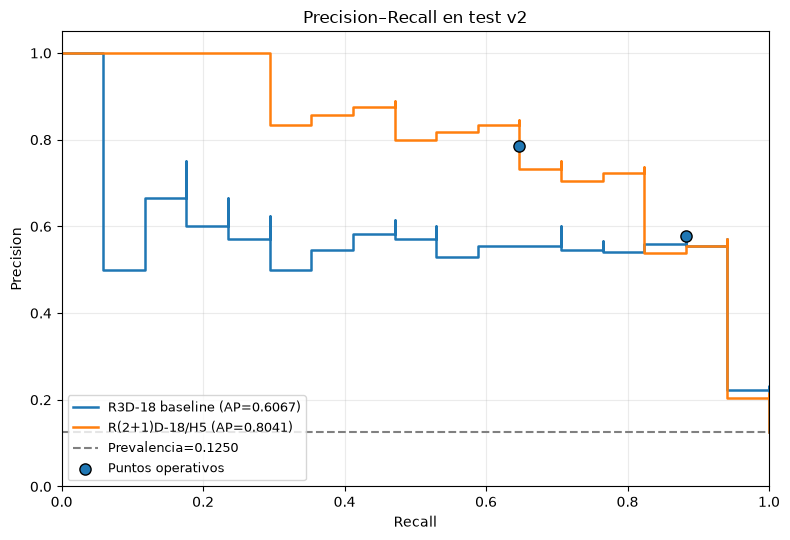

In [12]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve
)

assert len(y) == 136
assert int(y.sum()) == 17

fig, ax = plt.subplots(figsize=(8, 5.5))

for scores, nombre in [
    (p_baseline, "R3D-18 baseline"),
    (p_final, "R(2+1)D-18/H5")
]:
    precision, recall, _ = precision_recall_curve(
        y, scores
    )

    ap = average_precision_score(y, scores)

    ax.step(
        recall[::-1],
        precision[::-1],
        where="post",
        linewidth=1.8,
        label=f"{nombre} (AP={ap:.4f})"
    )

ax.axhline(
    y.mean(),
    color="gray",
    linestyle="--",
    label=f"Prevalencia={y.mean():.4f}"
)

# Puntos operativos fijados en validation
ax.scatter(
    [0.8824, 0.6471],
    [0.5769, 0.7857],
    marker="o",
    s=65,
    edgecolors="black",
    zorder=5,
    label="Puntos operativos"
)

ax.set(
    xlabel="Recall",
    ylabel="Precision",
    title="Precision–Recall en test v2",
    xlim=(0, 1),
    ylim=(0, 1.05)
)

ax.grid(alpha=0.25)
ax.legend(fontsize=9, loc="lower left")

fig.tight_layout()

assert abs(average_precision_score(y, p_baseline) - 0.6067) < 0.0001
assert abs(average_precision_score(y, p_final) - 0.8041) < 0.0001

ruta_salida = REPO_DIR / "figuras"
ruta_salida.mkdir(parents=True, exist_ok=True)

fig.savefig(
    ruta_salida / "pr_baseline_vs_h5_test_v2.pdf",
    bbox_inches="tight"
)

plt.show()

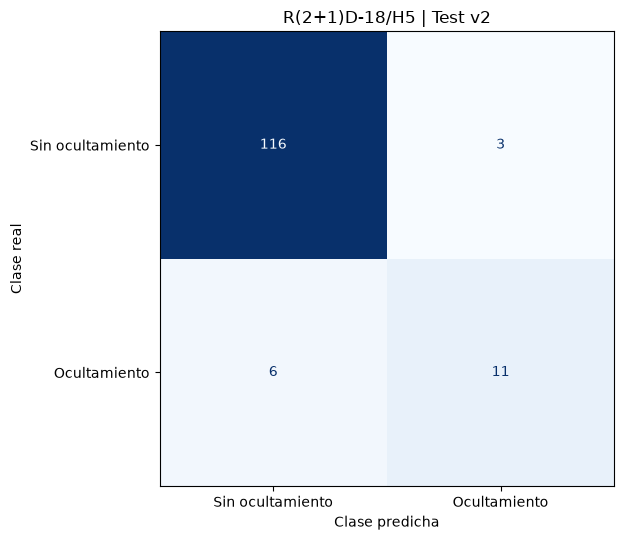

In [13]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_true = np.asarray(y, dtype=int).ravel()
scores = np.asarray(p_final, dtype=float).ravel()

# Threshold seleccionado previamente en validation
threshold_h5 = 0.99690056

y_pred = (scores >= threshold_h5).astype(int)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

# Verificación contra Avance 5
np.testing.assert_array_equal(
    cm,
    np.array([
        [116, 3],
        [6, 11]
    ])
)

fig, ax = plt.subplots(figsize=(6.5, 5.5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Sin ocultamiento",
        "Ocultamiento"
    ]
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False,
    cmap="Blues"
)

ax.set_title("R(2+1)D-18/H5 | Test v2")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")

fig.tight_layout()

# Guardar en el repositorio del notebook
ruta_salida = REPO_DIR / "figuras"
ruta_salida.mkdir(parents=True, exist_ok=True)

fig.savefig(
    ruta_salida / "cm_h5_test_v2.pdf",
    bbox_inches="tight"
)

plt.show()


## 7. Experimento controlado: precisión numérica de Softmax en validation

### Objetivo

Durante la revisión del proyecto con BNext se identificó una posible explicación de la diferencia entre el Average Precision (AP) histórico de R(2+1)D-18/H5 en el Avance 4 (0.7554) y el valor reproducible del Avance 5 (0.7720).

La hipótesis es que esta discrepancia se originó en la precisión numérica utilizada para calcular `softmax`, y no en cambios del checkpoint, las etiquetas o el conjunto de evaluación.

El objetivo del experimento es comprobar si el cálculo de `softmax` en FP16 y FP32 puede explicar la diferencia observada.

### Procedimiento

Se utilizan los mismos 136 clips de `validation`, el mismo checkpoint R(2+1)D-18/H5 y los mismos logits obtenidos mediante inferencia.

La única variable experimental es la precisión numérica del posprocesamiento:

1. **Softmax FP16:** calcular `softmax` directamente sobre logits en formato `float16`.
2. **Softmax FP32:** convertir los mismos logits a `float32` antes de aplicar `softmax`.

Para ambas variantes se calculan:

- Average Precision (AP).
- Número de scores de probabilidad únicos.
- Cantidad de probabilidades saturadas en 1.0.
- Diferencia de AP entre ambas precisiones.

El experimento mantiene constantes los datos, las etiquetas y los parámetros del modelo. Tampoco modifica el threshold seleccionado anteriormente ni utiliza `test` para tomar decisiones.

### Interpretación esperada

El análisis permitirá determinar si el redondeo numérico de FP16 produce empates entre probabilidades o saturación de scores que alteren el cálculo de Average Precision.

AP depende del ordenamiento de los scores, por lo que una reducción de precisión numérica puede modificar su valor incluso cuando las predicciones provienen del mismo modelo.

Si las dos variantes reproducen los valores históricos de los Avances 4 y 5, se contará con evidencia experimental para explicar la discrepancia.

Cualquier diferencia observada corresponderá al procedimiento de cálculo de probabilidades, no a una mejora en los parámetros aprendidos por el modelo.

### Reproducibilidad

Las predicciones y métricas se almacenan como artefactos reproducibles.

La generación de estos artefactos requiere activación explícita. En las ejecuciones normales del notebook se reutilizan los resultados validados, evitando repetir inferencias innecesarias.

No se requiere reentrenamiento ni modificación del checkpoint.

### Limitaciones

El experimento modifica únicamente la precisión del cálculo de `softmax`. No compara una ejecución completa del modelo en FP16 contra otra ejecutada íntegramente en FP32.

Además, la prueba se realiza sobre `validation`, por lo que sus resultados explican el comportamiento numérico observado en ese conjunto, sin demostrar automáticamente que la misma diferencia se presente en `test`.

La comprobación independiente sobre test v2 se documenta en la sección siguiente.


In [15]:

# ============================================================
# A6 - Prueba controlada de precisión de Softmax
#
# Objetivo:
# Comparar AP al calcular softmax en float16 y float32
# utilizando exactamente los mismos logits de R(2+1)D-18/H5.
#
# No entrena modelos.
# No modifica artefactos de A4 ni A5.
# ============================================================

from pathlib import Path
import os
import json
import hashlib

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision.models import video as video_models
from sklearn.metrics import average_precision_score


# ------------------------------------------------------------
# 1. Configuración
# ------------------------------------------------------------

# Activar True únicamente para generar el experimento.
# Después cambiar a False para Restart Kernel + Run All.
GENERAR_PRUEBA_SOFTMAX_A6 = False


# ------------------------------------------------------------
# 2. Localizar repositorio y artefactos
# ------------------------------------------------------------

if "REPO_DIR" not in globals():
    raise RuntimeError(
        "Debe ejecutarse primero la celda de localización "
        "del repositorio."
    )

if "VideoDatasetRGB" not in globals():
    raise RuntimeError(
        "Debe ejecutarse primero la celda "
        "'A6 - Dependencias autocontenidas para inferencia RGB'."
    )

MARCADOR_SOFTMAX_A6 = (
    Path("Datos")
    / "Preparacion_Datasets"
    / "avance4_split_ground_truth_v2.csv"
)

REPO_RAIZ_SOFTMAX_A6 = None

for candidato in [
    Path(REPO_DIR),
    *Path(REPO_DIR).parents
]:
    if (candidato / MARCADOR_SOFTMAX_A6).is_file():
        REPO_RAIZ_SOFTMAX_A6 = candidato.resolve()
        break

if REPO_RAIZ_SOFTMAX_A6 is None:
    raise FileNotFoundError(
        "No se encontró avance4_split_ground_truth_v2.csv "
        "desde la raíz del repositorio."
    )

ruta_split = (
    REPO_RAIZ_SOFTMAX_A6 / MARCADOR_SOFTMAX_A6
)

ruta_checkpoint = (
    REPO_RAIZ_SOFTMAX_A6
    / "Notebooks"
    / "checkpoints"
    / "r2plus1d_18_avance4_h5.pt"
)

ruta_salida = (
    REPO_RAIZ_SOFTMAX_A6
    / "Datos"
    / "Preparacion_Datasets"
    / "avance6_artefactos"
)

archivo_scores = (
    ruta_salida / "softmax_precision_h5_val.csv"
)

archivo_meta = (
    ruta_salida / "softmax_precision_h5_val.json"
)

if not ruta_checkpoint.is_file():
    raise FileNotFoundError(
        f"Checkpoint H5 no encontrado: {ruta_checkpoint}"
    )


# ------------------------------------------------------------
# 3. Recuperar validation
# ------------------------------------------------------------

df_split_softmax = pd.read_csv(ruta_split)

df_val_softmax = (
    df_split_softmax[
        df_split_softmax["split"]
        .astype(str)
        .str.lower()
        .isin(["val", "validation"])
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(df_val_softmax) == 136
assert int(df_val_softmax["clase_binaria"].sum()) == 30
assert df_val_softmax["grupo_experimental"].nunique() == 9
assert df_val_softmax["clip_id"].is_unique
assert "nombre_clip" in df_val_softmax.columns

print("=== VALIDATION ===")
print("Clips:", len(df_val_softmax))
print(
    "Positivos:",
    int(df_val_softmax["clase_binaria"].sum())
)
print(
    "Grupos:",
    df_val_softmax["grupo_experimental"].nunique()
)


# ------------------------------------------------------------
# 4. Configuración independiente de inferencia
# ------------------------------------------------------------

DEVICE_SOFTMAX_A6 = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

transform_softmax_a6 = (
    video_models
    .R2Plus1D_18_Weights
    .DEFAULT
    .transforms()
)

ruta_clips_softmax = os.environ.get("BNEXT_CLIPS_DIR")

if GENERAR_PRUEBA_SOFTMAX_A6:

    if DEVICE_SOFTMAX_A6.type != "cuda":
        raise RuntimeError(
            "La generación necesita GPU CUDA "
            "para obtener logits float16 mediante AMP."
        )

    if not ruta_clips_softmax:
        raise RuntimeError(
            "Configure BNEXT_CLIPS_DIR antes de generar."
        )

    CLIPS_DIR_SOFTMAX_A6 = Path(ruta_clips_softmax)

    if not CLIPS_DIR_SOFTMAX_A6.is_dir():
        raise FileNotFoundError(
            "BNEXT_CLIPS_DIR no es un directorio válido."
        )


# ------------------------------------------------------------
# 5. Metadatos para trazabilidad
# ------------------------------------------------------------

def sha256_archivo_softmax(ruta):
    h = hashlib.sha256()

    with open(ruta, "rb") as archivo:
        for bloque in iter(
            lambda: archivo.read(1024 * 1024),
            b""
        ):
            h.update(bloque)

    return h.hexdigest()


procedencia_softmax = {
    "experimento": "A6_softmax_precision_h5_validation",
    "version_protocolo": 1,
    "checkpoint_sha256": sha256_archivo_softmax(
        ruta_checkpoint
    ),
    "split_sha256": sha256_archivo_softmax(
        ruta_split
    ),
    "modelo": "R(2+1)D-18/H5",
    "particion": "validation",
    "n_clips": 136,
    "n_positivos": 30,
    "n_grupos": 9,
    "num_frames": 16,
    "transform": "R2Plus1D_18_Weights.DEFAULT",
    "forward": "CUDA autocast float16",
    "softmax_variantes": ["float16", "float32"],
    "torch_version": str(torch.__version__)
}


# ------------------------------------------------------------
# 6. Generación controlada
# ------------------------------------------------------------

if GENERAR_PRUEBA_SOFTMAX_A6:

    # Evitar sobrescribir incluso artefactos previos de A6.
    if archivo_scores.exists() or archivo_meta.exists():
        raise FileExistsError(
            "Ya existen artefactos de esta prueba. "
            "Cambie la bandera a False para recuperarlos. "
            "No se sobrescribieron archivos."
        )

    dataset_val_softmax = VideoDatasetRGB(
        df_val_softmax,
        CLIPS_DIR_SOFTMAX_A6,
        transform_softmax_a6
    )

    loader_val_softmax = DataLoader(
        dataset_val_softmax,
        batch_size=16,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    # Reconstruir H5 de manera independiente.
    # No se utiliza la variable modelo_a6.
    checkpoint_softmax = torch.load(
        ruta_checkpoint,
        map_location="cpu",
        weights_only=False
    )

    modelo_softmax_a6 = video_models.r2plus1d_18(
        weights=None
    )

    modelo_softmax_a6.fc = nn.Linear(
        modelo_softmax_a6.fc.in_features,
        2
    )

    modelo_softmax_a6.load_state_dict(
        checkpoint_softmax["model_state_dict"]
    )

    modelo_softmax_a6 = (
        modelo_softmax_a6
        .to(DEVICE_SOFTMAX_A6)
        .eval()
    )

    etiquetas_softmax = []
    probabilidades_fp16 = []
    probabilidades_fp32 = []

    print("\nEjecutando inferencia controlada...")

    with torch.inference_mode():

        for clips, labels in loader_val_softmax:

            clips = clips.to(
                DEVICE_SOFTMAX_A6,
                non_blocking=True
            )

            # Un único forward pass.
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = modelo_softmax_a6(clips)

            if logits.dtype != torch.float16:
                raise RuntimeError(
                    "Los logits no son float16. "
                    "La comparación no sería válida."
                )

            # Variante A:
            # Softmax directamente en float16.
            p16 = torch.softmax(
                logits,
                dim=1
            )[:, 1]

            # Variante B:
            # Los mismos logits, convertidos a float32.
            p32 = torch.softmax(
                logits.float(),
                dim=1
            )[:, 1]

            if p16.dtype != torch.float16:
                raise RuntimeError(
                    "Softmax A no produjo float16."
                )

            if p32.dtype != torch.float32:
                raise RuntimeError(
                    "Softmax B no produjo float32."
                )

            etiquetas_softmax.append(
                labels.cpu().numpy()
            )

            probabilidades_fp16.append(
                p16.float().cpu().numpy()
            )

            probabilidades_fp32.append(
                p32.cpu().numpy()
            )

    y_obtenido = np.concatenate(
        etiquetas_softmax
    )

    np.testing.assert_array_equal(
        y_obtenido,
        df_val_softmax["clase_binaria"].to_numpy(dtype=int)
    )

    resultado_softmax = df_val_softmax[
        [
            "clip_id",
            "grupo_experimental",
            "clase_binaria"
        ]
    ].copy()

    resultado_softmax["p_softmax_fp16"] = np.concatenate(
        probabilidades_fp16
    )

    resultado_softmax["p_softmax_fp32"] = np.concatenate(
        probabilidades_fp32
    )

    # Guardar exclusivamente en avance6_artefactos.
    ruta_salida.mkdir(
        parents=True,
        exist_ok=True
    )

    resultado_softmax.to_csv(
        archivo_scores,
        index=False
    )

    archivo_meta.write_text(
        json.dumps(
            procedencia_softmax,
            indent=2
        ),
        encoding="utf-8"
    )

    print("Artefactos A6 generados correctamente.")

    # Liberar recursos de este experimento.
    del modelo_softmax_a6
    del checkpoint_softmax

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 7. Recuperación para Restart Kernel + Run All
# ------------------------------------------------------------

else:

    if not archivo_scores.is_file():
        raise FileNotFoundError(
            "Falta softmax_precision_h5_val.csv. "
            "Active GENERAR_PRUEBA_SOFTMAX_A6=True "
            "para generarlo por primera vez."
        )

    if not archivo_meta.is_file():
        raise FileNotFoundError(
            "Falta softmax_precision_h5_val.json. "
            "Active GENERAR_PRUEBA_SOFTMAX_A6=True "
            "para generarlo por primera vez."
        )

    meta_guardada = json.loads(
        archivo_meta.read_text(encoding="utf-8")
    )

    if meta_guardada != procedencia_softmax:
        raise RuntimeError(
            "Los metadatos del experimento no coinciden "
            "con la configuración actual."
        )

    resultado_softmax = pd.read_csv(
        archivo_scores
    )

    print("\nArtefactos A6 recuperados y validados.")


# ------------------------------------------------------------
# 8. Validar integridad
# ------------------------------------------------------------

assert len(resultado_softmax) == 136

np.testing.assert_array_equal(
    resultado_softmax["clip_id"].astype(str).to_numpy(),
    df_val_softmax["clip_id"].astype(str).to_numpy()
)

np.testing.assert_array_equal(
    resultado_softmax["grupo_experimental"]
    .astype(str).to_numpy(),
    df_val_softmax["grupo_experimental"]
    .astype(str).to_numpy()
)

np.testing.assert_array_equal(
    resultado_softmax["clase_binaria"].to_numpy(dtype=int),
    df_val_softmax["clase_binaria"].to_numpy(dtype=int)
)

y_softmax = resultado_softmax[
    "clase_binaria"
].to_numpy(dtype=int)

p16 = resultado_softmax[
    "p_softmax_fp16"
].to_numpy(dtype=float)

p32 = resultado_softmax[
    "p_softmax_fp32"
].to_numpy(dtype=float)

assert np.isfinite(p16).all()
assert np.isfinite(p32).all()

assert ((p16 >= 0) & (p16 <= 1)).all()
assert ((p32 >= 0) & (p32 <= 1)).all()


# ------------------------------------------------------------
# 9. Resultados
# ------------------------------------------------------------

ap_fp16 = average_precision_score(
    y_softmax, p16
)

ap_fp32 = average_precision_score(
    y_softmax, p32
)

tabla_softmax = pd.DataFrame([
    {
        "Precisión Softmax": "float16",
        "AP": ap_fp16,
        "Scores únicos": len(np.unique(p16)),
        "Scores exactamente 1.0": int((p16 == 1).sum())
    },
    {
        "Precisión Softmax": "float32",
        "AP": ap_fp32,
        "Scores únicos": len(np.unique(p32)),
        "Scores exactamente 1.0": int((p32 == 1).sum())
    }
])

print("\n=== PRUEBA CONTROLADA SOFTMAX ===")

display(
    tabla_softmax.style.format({
        "AP": "{:.8f}"
    })
)

print(
    "\nDiferencia AP (FP32 - FP16):",
    f"{ap_fp32 - ap_fp16:.8f}"
)

print(
    "Diferencia máxima entre scores:",
    f"{np.max(np.abs(p32 - p16)):.8f}"
)

print("\nReferencias de los entregables:")
print("Avance 4 validation AP: 0.7554")
print("Avance 5 validation AP: 0.7720")


=== VALIDATION ===
Clips: 136
Positivos: 30
Grupos: 9

Artefactos A6 recuperados y validados.

=== PRUEBA CONTROLADA SOFTMAX ===


,Precisión Softmax,AP,Scores únicos,Scores exactamente 1.0
0,float16,0.75542816,119,14
1,float32,0.77204625,136,0



Diferencia AP (FP32 - FP16): 0.01661809
Diferencia máxima entre scores: 0.00023870

Referencias de los entregables:
Avance 4 validation AP: 0.7554
Avance 5 validation AP: 0.7720


### Resultados e interpretación: precisión numérica de Softmax

La prueba controlada reprodujo los valores de Average Precision registrados en los Avances 4 y 5 para `validation`, utilizando el mismo checkpoint R(2+1)D-18/H5, los mismos 136 clips, las mismas etiquetas y los mismos logits.

| Indicador | Softmax float16 | Softmax float32 |
|---|---:|---:|
| Average Precision | 0.75542816 | 0.77204625 |
| Scores únicos | 119 | 136 |
| Scores exactamente iguales a 1.0 | 14 | 0 |

La diferencia absoluta de AP fue **0.01661809**. El cálculo en `float16` produjo empates y saturación de probabilidades en 1.0, mientras que `float32` conservó una mayor resolución numérica. Aunque la diferencia máxima entre probabilidades fue de 0.00023872, resultó suficiente para modificar el ordenamiento de las predicciones y, por consecuencia, Average Precision.

**Conclusión:** se confirmó que la precisión numérica del cálculo de `softmax` explica la discrepancia histórica de AP en `validation` entre ambos avances, reproduciendo los resultados a cuatro decimales.


**Alcance:** esta prueba se realizó sobre `validation`. Posteriormente, se completó una auditoría independiente sobre `test v2`, que también reprodujo las diferencias históricas de AP entre los Avances 4 y 5. Sus resultados se documentan en la sección 8.

A partir de estas verificaciones se establece `softmax` en `float32` como procedimiento numérico de referencia, independientemente del uso de AMP durante el forward del modelo. Esto permite mantener un criterio consistente al comparar las métricas de los distintos avances.



## Prueba controlada de precisión de Softmax: baseline R3D-18

### 1. Motivación

La prueba controlada realizada con R(2+1)D-18/H5 demostró que la diferencia de Average Precision (AP) entre los Avances 4 y 5 en `validation` se debía a la precisión numérica utilizada para calcular `softmax`. El cálculo en `float16` introducía empates y saturación de scores que afectaban el ordenamiento utilizado por AP.

Durante la revisión del baseline R3D-18 del Avance 3 se identificó que su procedimiento de evaluación también aplicaba `softmax` directamente sobre los logits generados bajo precisión mixta (AMP).

Por ello, se consideró necesario comprobar si el AP histórico del baseline también estaba afectado por la precisión numérica. Esta verificación es relevante para el Avance 6 porque R3D-18 constituye la referencia utilizada para calcular la diferencia de desempeño frente al candidato final R(2+1)D-18/H5.

### 2. Objetivo

Determinar si calcular `softmax` en `float16` o `float32` modifica el Average Precision del baseline R3D-18 sobre `validation`, manteniendo constantes el modelo, los datos y los logits.

También se busca reproducir el AP histórico de 0.6345 reportado en el Avance 3.

### 3. Diseño experimental

La prueba utiliza:

- El checkpoint original `r3d18_baseline_best.pt`.
- Los 136 clips de `validation`, con 30 positivos y nueve grupos experimentales.
- El preprocesamiento original del Avance 3, incluyendo muestreo temporal, redimensionamiento directo a 112 × 112 y normalización Kinetics.
- Un único forward pass por batch mediante AMP con logits en `float16`.
- Dos cálculos de `softmax` sobre exactamente los mismos logits:

```python
# Procedimiento histórico: Softmax en float16
p16 = torch.softmax(logits, dim=1)[:, 1]

# Procedimiento alternativo: Softmax en float32
p32 = torch.softmax(logits.float(), dim=1)[:, 1]
```

Se compararán AP, número de scores únicos, probabilidades saturadas en 1.0 y diferencia máxima entre scores.

La prueba no modifica pesos, no reentrena el modelo ni ajusta hiperparámetros o thresholds. Los resultados se almacenarán en artefactos independientes para conservar su trazabilidad y permitir su recuperación sin repetir la inferencia.


In [16]:

# ============================================================
# A6 - Prueba controlada de precisión de Softmax: R3D-18
#
# Partición: validation (136 clips, 30 positivos, 9 grupos).
# Un solo forward pass, dos cálculos de softmax.
#
# No entrena modelos.
# No modifica artefactos históricos.
# Reproduce el preprocesamiento original del Avance 3.
# ============================================================

import os
import json
import hashlib
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader
from torchvision.models.video import r3d_18
from sklearn.metrics import average_precision_score


# Primera ejecución: True
# Después de generar y verificar los artefactos: False
GENERAR_SOFTMAX_BASELINE_A6 = False

assert "REPO_DIR" in globals()
assert "VideoDatasetRGB" in globals()
assert "cargar_frames_rgb" in globals()

ruta_split_base = (
    REPO_DIR / "Datos" / "Preparacion_Datasets"
    / "avance4_split_ground_truth_v2.csv"
)

ruta_checkpoint_base = (
    REPO_DIR / "Notebooks" / "checkpoints"
    / "r3d18_baseline_best.pt"
)

ruta_artefactos_base = (
    REPO_DIR / "Datos" / "Preparacion_Datasets"
    / "avance6_artefactos"
)

ruta_csv_base = (
    ruta_artefactos_base
    / "softmax_precision_baseline_val.csv"
)

ruta_json_base = (
    ruta_artefactos_base
    / "softmax_precision_baseline_val.json"
)

for ruta in [ruta_split_base, ruta_checkpoint_base]:
    if not ruta.is_file():
        raise FileNotFoundError(ruta)


# ------------------------------------------------------------
# 1. Recuperar validation
# ------------------------------------------------------------

df_base_val = pd.read_csv(ruta_split_base)

df_base_val = (
    df_base_val.loc[
        df_base_val["split"].astype(str).str.lower()
        .isin(["val", "validation"])
    ]
    .reset_index(drop=True)
    .copy()
)

assert len(df_base_val) == 136
assert int(df_base_val["clase_binaria"].sum()) == 30
assert df_base_val["grupo_experimental"].nunique() == 9
assert df_base_val["clip_id"].is_unique

print("Validation:", len(df_base_val), "clips")


# ------------------------------------------------------------
# 2. Transform original del Avance 3
#
# La función cargar_frames_rgb del A6 entrega:
# (T, C, H, W), uint8, RGB.
#
# El Avance 3 aplicaba resize directo de cada frame
# a 112x112 y normalización Kinetics.
# ------------------------------------------------------------

KINETICS_MEAN_BASE = np.array(
    [0.43216, 0.394666, 0.37645],
    dtype=np.float32
)

KINETICS_STD_BASE = np.array(
    [0.22803, 0.22145, 0.216989],
    dtype=np.float32
)


def transform_baseline_a6(clip):
    frames_rgb = (
        clip.permute(0, 2, 3, 1)
        .contiguous()
        .numpy()
    )

    frames = []

    for frame in frames_rgb:
        frame = cv2.resize(
            frame,
            (112, 112),
            interpolation=cv2.INTER_LINEAR
        )

        frame = frame.astype(np.float32) / 255.0

        frame = (
            frame - KINETICS_MEAN_BASE
        ) / KINETICS_STD_BASE

        frames.append(frame)

    tensor = np.stack(frames, axis=0)
    tensor = np.transpose(tensor, (3, 0, 1, 2))

    return torch.from_numpy(tensor.copy()).float()


# ------------------------------------------------------------
# 3. Trazabilidad
# ------------------------------------------------------------

def sha256_baseline_a6(ruta):
    h = hashlib.sha256()

    with open(ruta, "rb") as f:
        for bloque in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(bloque)

    return h.hexdigest()


meta_base = {
    "experimento": "A6_softmax_precision_baseline_validation",
    "version_protocolo": 1,
    "modelo": "R3D-18 baseline Avance 3",
    "checkpoint_sha256": sha256_baseline_a6(
        ruta_checkpoint_base
    ),
    "split_sha256": sha256_baseline_a6(
        ruta_split_base
    ),
    "particion": "validation",
    "n_clips": 136,
    "n_positivos": 30,
    "n_grupos": 9,
    "num_frames": 16,
    "preprocesamiento": (
        "Avance 3: muestreo uniforme, resize directo "
        "112x112 INTER_LINEAR, normalizacion Kinetics"
    ),
    "forward": "CUDA autocast float16",
    "softmax": ["float16", "float32"],
    "torch_version": str(torch.__version__)
}


# ------------------------------------------------------------
# 4. Generación controlada
# ------------------------------------------------------------

if GENERAR_SOFTMAX_BASELINE_A6:

    if not torch.cuda.is_available():
        raise RuntimeError(
            "Se requiere CUDA para reproducir AMP FP16."
        )

    if ruta_csv_base.exists() or ruta_json_base.exists():
        raise FileExistsError(
            "Ya existen artefactos. Utilice la bandera False "
            "para recuperarlos; no se sobrescribió nada."
        )

    clips_env = os.environ.get("BNEXT_CLIPS_DIR")

    if not clips_env:
        raise RuntimeError(
            "Debe configurar BNEXT_CLIPS_DIR."
        )

    clips_dir_base = Path(clips_env)

    if not clips_dir_base.is_dir():
        raise FileNotFoundError(clips_dir_base)

    dataset_base = VideoDatasetRGB(
        df_base_val,
        clips_dir_base,
        transform_baseline_a6
    )

    loader_base = DataLoader(
        dataset_base,
        batch_size=16,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    ckpt_base = torch.load(
        ruta_checkpoint_base,
        map_location="cpu",
        weights_only=False
    )

    modelo_base = r3d_18(weights=None)
    modelo_base.fc = nn.Linear(
        modelo_base.fc.in_features, 2
    )

    modelo_base.load_state_dict(
        ckpt_base["model_state_dict"]
    )

    modelo_base = modelo_base.cuda().eval()

    y_obtenido = []
    scores_base_16 = []
    scores_base_32 = []

    with torch.inference_mode():

        for clips, labels in loader_base:

            clips = clips.cuda(non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = modelo_base(clips)

            if logits.dtype != torch.float16:
                raise RuntimeError(
                    "Los logits no son FP16."
                )

            # Misma inferencia, distinta precisión numérica
            p16 = torch.softmax(
                logits, dim=1
            )[:, 1]

            p32 = torch.softmax(
                logits.float(), dim=1
            )[:, 1]

            assert p16.dtype == torch.float16
            assert p32.dtype == torch.float32

            y_obtenido.extend(labels.numpy())
            scores_base_16.extend(
                p16.float().cpu().numpy()
            )
            scores_base_32.extend(
                p32.cpu().numpy()
            )

    np.testing.assert_array_equal(
        np.asarray(y_obtenido, dtype=int),
        df_base_val["clase_binaria"].to_numpy(dtype=int)
    )

    resultado_base = df_base_val[
        ["clip_id", "grupo_experimental", "clase_binaria"]
    ].copy()

    resultado_base["p_softmax_fp16"] = scores_base_16
    resultado_base["p_softmax_fp32"] = scores_base_32

    ruta_artefactos_base.mkdir(
        parents=True, exist_ok=True
    )

    resultado_base.to_csv(
        ruta_csv_base, index=False
    )

    ruta_json_base.write_text(
        json.dumps(meta_base, indent=2),
        encoding="utf-8"
    )

    del modelo_base, ckpt_base
    torch.cuda.empty_cache()

    print("Artefactos del baseline generados.")

else:

    if not ruta_csv_base.is_file():
        raise FileNotFoundError(
            "Falta el CSV. Ejecute primero con "
            "GENERAR_SOFTMAX_BASELINE_A6=True."
        )

    if not ruta_json_base.is_file():
        raise FileNotFoundError(
            "Falta el JSON del experimento."
        )

    meta_existente = json.loads(
        ruta_json_base.read_text(encoding="utf-8")
    )

    if meta_existente != meta_base:
        raise RuntimeError(
            "La procedencia guardada no coincide "
            "con la configuración actual."
        )

    resultado_base = pd.read_csv(ruta_csv_base)

    print("Artefactos del baseline recuperados.")


# ------------------------------------------------------------
# 5. Verificación de identidad e integridad
# ------------------------------------------------------------

assert len(resultado_base) == 136

for columna in [
    "clip_id",
    "grupo_experimental",
    "clase_binaria"
]:
    np.testing.assert_array_equal(
        resultado_base[columna].astype(str).to_numpy(),
        df_base_val[columna].astype(str).to_numpy()
    )

y_base = resultado_base[
    "clase_binaria"
].to_numpy(dtype=int)

p_base_16 = resultado_base[
    "p_softmax_fp16"
].to_numpy(dtype=float)

p_base_32 = resultado_base[
    "p_softmax_fp32"
].to_numpy(dtype=float)

assert np.isfinite(p_base_16).all()
assert np.isfinite(p_base_32).all()

assert ((p_base_16 >= 0) & (p_base_16 <= 1)).all()
assert ((p_base_32 >= 0) & (p_base_32 <= 1)).all()


# ------------------------------------------------------------
# 6. Métricas y comparación histórica
# ------------------------------------------------------------

ap_base_16 = average_precision_score(
    y_base, p_base_16
)

ap_base_32 = average_precision_score(
    y_base, p_base_32
)

tabla_baseline_softmax = pd.DataFrame([
    {
        "Softmax": "float16",
        "AP": ap_base_16,
        "Scores únicos": np.unique(p_base_16).size,
        "Scores iguales a 1": int((p_base_16 == 1).sum())
    },
    {
        "Softmax": "float32",
        "AP": ap_base_32,
        "Scores únicos": np.unique(p_base_32).size,
        "Scores iguales a 1": int((p_base_32 == 1).sum())
    }
])

print("\n=== PRUEBA CONTROLADA R3D-18 ===")

display(
    tabla_baseline_softmax.style.format({
        "AP": "{:.8f}"
    })
)

print(
    "Delta AP (FP32 - FP16):",
    f"{ap_base_32 - ap_base_16:.8f}"
)

print(
    "Diferencia máxima entre scores:",
    f"{np.max(np.abs(p_base_32 - p_base_16)):.8f}"
)

print(
    "Reproduce AP histórico de validation (0.6345):",
    abs(ap_base_16 - 0.6345) < 0.0001
)


Validation: 136 clips
Artefactos del baseline recuperados.

=== PRUEBA CONTROLADA R3D-18 ===


,Softmax,AP,Scores únicos,Scores iguales a 1
0,float16,0.63449503,135,0
1,float32,0.63449503,135,0


Delta AP (FP32 - FP16): 0.00000000
Diferencia máxima entre scores: 0.00021970
Reproduce AP histórico de validation (0.6345): True



### 4. Resultados obtenidos

La prueba reprodujo correctamente el Average Precision histórico del baseline R3D-18 en `validation`.

| Indicador | Softmax float16 | Softmax float32 |
|---|---:|---:|
| Average Precision | **0.63449503** | **0.63449503** |
| Scores únicos | 135 | 135 |
| Scores exactamente iguales a 1.0 | 0 | 0 |

**Diferencia absoluta de AP:** 0.00000000.

**Diferencia máxima entre probabilidades:** 0.00021970.

El AP obtenido con `float16` reproduce el valor de 0.6345 registrado en el Avance 3.

Aunque existen diferencias numéricas entre las probabilidades calculadas con ambas precisiones, estas no modificaron el Average Precision del baseline sobre los 136 clips de `validation`.

### 5. Comparación con la prueba de R(2+1)D-18/H5

| Modelo | AP float16 | AP float32 | Diferencia |
|---|---:|---:|---:|
| R3D-18 baseline | 0.63449503 | 0.63449503 | 0.00000000 |
| R(2+1)D-18/H5 | 0.75542816 | 0.77204625 | +0.01661809 |

Los resultados muestran comportamientos diferentes ante el cambio de precisión.

En R(2+1)D-18/H5, `softmax` en `float16` produjo 119 scores únicos y 14 probabilidades saturadas en 1.0, frente a 136 scores únicos y ninguna saturación en `float32`. Esta pérdida de resolución numérica afectó el cálculo de AP.

En R3D-18, ambas variantes conservaron 135 scores únicos y ninguna probabilidad saturada en 1.0. El AP permaneció inalterado.

Por tanto, el impacto de la precisión numérica no es uniforme entre modelos. Depende de la distribución de sus logits y de cómo el redondeo modifica los empates y el ordenamiento de las predicciones.

### 6. Conclusiones

**La prueba confirmó que el AP histórico del baseline R3D-18 en `validation` es reproducible y no cambia al calcular `softmax` en `float32` sobre los mismos logits FP16.**

Este resultado permite establecer que:

1. La discrepancia histórica de AP de R(2+1)D-18/H5 en `validation` sí se explica por la precisión de `softmax`, mientras que el baseline no presenta ese efecto sobre su AP en la partición evaluada.
2. La precisión numérica del posprocesamiento puede afectar métricas de ranking, pero su impacto debe comprobarse individualmente para cada modelo y conjunto de datos.
3. No es necesario modificar el AP histórico de 0.6345 del baseline en `validation`.
4. Se mantiene la recomendación de estandarizar el cálculo de `softmax` en `float32` para futuras evaluaciones, aun cuando el forward pass se ejecute con AMP FP16.

La comprobación no representa una mejora del modelo, un cambio de pesos ni un nuevo entrenamiento.


### Limitaciones y comprobación posterior

El experimento inicial se realizó sobre `validation` y confirmó que el AP del baseline R3D-18 permanecía inalterado al calcular `softmax` en FP16 o FP32.

Posteriormente, se realizó la misma comprobación sobre los 136 clips de `test v2`. El AP del baseline permaneció en 0.60673571 bajo ambas precisiones numéricas.

Esto confirma que, en las dos particiones evaluadas, el cambio de precisión no modificó el AP del baseline.

Sin embargo, esta invariancia no debe generalizarse a otros modelos, datasets o procedimientos de evaluación.

Tampoco demuestra que todas las métricas dependientes del threshold o las etapas históricas de selección de checkpoints sean invariantes.

Las verificaciones conservaron los checkpoints y thresholds originales, sin modificar las decisiones experimentales ni utilizar `test` para optimizar modelos.


In [17]:

# ============================================================
# A6 - Prueba controlada Softmax FP16 vs FP32 en test v2
# Modelos: R3D-18 baseline y R(2+1)D-18/H5
# No reentrena, no selecciona thresholds, no sobrescribe.
# ============================================================

import os
import json
import hashlib
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision

from pathlib import Path
from torch.utils.data import DataLoader
from torchvision.models import video as video_models
from sklearn.metrics import average_precision_score, confusion_matrix

# Primera ejecución: True. Posteriormente: False.
GENERAR_SOFTMAX_TEST_A6 = False

assert "REPO_DIR" in globals()
assert "VideoDatasetRGB" in globals()

raiz = Path(REPO_DIR)

ruta_split_test = (
    raiz / "Datos" / "Preparacion_Datasets"
    / "avance4_split_ground_truth_v2.csv"
)
ruta_baseline = (
    raiz / "Notebooks" / "checkpoints"
    / "r3d18_baseline_best.pt"
)
ruta_h5 = (
    raiz / "Notebooks" / "checkpoints"
    / "r2plus1d_18_avance4_h5.pt"
)
ruta_hist_baseline = (
    raiz / "Notebooks" / "checkpoints"
    / "r3d18_baseline_test_predictions.csv"
)
ruta_hist_h5 = (
    raiz / "Datos" / "Preparacion_Datasets"
    / "avance5_artefactos"
    / "predicciones_r2plus1d_h5_test.csv"
)
directorio_a6_test = (
    raiz / "Datos" / "Preparacion_Datasets"
    / "avance6_artefactos"
)
csv_test = directorio_a6_test / "softmax_precision_rgb_test_v2.csv"
json_test = directorio_a6_test / "softmax_precision_rgb_test_v2.json"

for ruta in (
    ruta_split_test, ruta_baseline, ruta_h5,
    ruta_hist_baseline, ruta_hist_h5
):
    if not ruta.is_file():
        raise FileNotFoundError(ruta)


def sha256_test_a6(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b""):
            h.update(bloque)
    return h.hexdigest()


# 1. Mismas observaciones de test v2
df_split_test = pd.read_csv(ruta_split_test)
elegibles = (
    df_split_test["elegible_avance4"]
    .astype(str).str.lower().isin(["true", "1"])
)
df_test_softmax = (
    df_split_test.loc[
        df_split_test["split"].eq("test") & elegibles
    ].reset_index(drop=True).copy()
)

assert len(df_test_softmax) == 136
assert int(df_test_softmax["clase_binaria"].sum()) == 17
assert df_test_softmax["grupo_experimental"].nunique() == 8
assert df_test_softmax["clip_id"].is_unique
assert "nombre_clip" in df_test_softmax.columns

print("Test v2:", len(df_test_softmax), "clips")
print("Positivos:", int(df_test_softmax["clase_binaria"].sum()))
print("Grupos:", df_test_softmax["grupo_experimental"].nunique())


# 2. Transform original R3D-18 del Avance 3
MEDIA_BASE = np.array(
    [0.43216, 0.394666, 0.37645],
    dtype=np.float32
)
STD_BASE = np.array(
    [0.22803, 0.22145, 0.216989],
    dtype=np.float32
)


def transform_r3d_test_a6(clip):
    # clip original: (T, C, H, W), RGB uint8
    frames = clip.permute(0, 2, 3, 1).numpy()
    procesados = []

    for frame in frames:
        frame = cv2.resize(
            frame, (112, 112),
            interpolation=cv2.INTER_LINEAR
        )
        frame = frame.astype(np.float32) / 255.0
        procesados.append(
            (frame - MEDIA_BASE) / STD_BASE
        )

    arreglo = np.stack(procesados)
    arreglo = np.transpose(arreglo, (3, 0, 1, 2))
    return torch.from_numpy(arreglo.copy()).float()


# 3. Transform original H5
transform_h5_test_a6 = (
    video_models.R2Plus1D_18_Weights.DEFAULT.transforms()
)


# 4. Procedencia del experimento
meta_test_esperada = {
    "experimento": "A6_softmax_precision_rgb_test_v2",
    "version_protocolo": 1,
    "particion": "test_v2",
    "n_clips": 136,
    "positivos": 17,
    "grupos": 8,
    "split_sha256": sha256_test_a6(ruta_split_test),
    "checkpoint_r3d18_sha256": sha256_test_a6(ruta_baseline),
    "checkpoint_h5_sha256": sha256_test_a6(ruta_h5),
    "predicciones_baseline_sha256": sha256_test_a6(
        ruta_hist_baseline
    ),
    "predicciones_h5_sha256": sha256_test_a6(ruta_hist_h5),
    "forward": "CUDA autocast float16",
    "softmax": ["float16", "float32"],
    "transform_r3d": "Avance 3: resize directo 112 y Kinetics",
    "transform_h5": "R2Plus1D_18_Weights.DEFAULT",
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__)
}


# 5. Inferencia controlada, una vez por arquitectura
def inferir_dos_precisiones_test(
    nombre, checkpoint_path, constructor, transform, clips_dir
):
    df_modelo = VideoDatasetRGB(
        df_test_softmax, clips_dir, transform
    )
    loader = DataLoader(
        df_modelo, batch_size=16, shuffle=False,
        num_workers=0, pin_memory=True
    )

    checkpoint = torch.load(
        checkpoint_path, map_location="cpu",
        weights_only=False
    )
    modelo = constructor(weights=None)
    modelo.fc = nn.Linear(modelo.fc.in_features, 2)
    modelo.load_state_dict(checkpoint["model_state_dict"])
    modelo = modelo.cuda().eval()

    etiquetas, lista16, lista32 = [], [], []

    with torch.inference_mode():
        for clips, y_batch in loader:
            clips = clips.cuda(non_blocking=True)

            with torch.autocast(
                device_type="cuda", dtype=torch.float16
            ):
                logits = modelo(clips)

            assert logits.dtype == torch.float16

            p16 = torch.softmax(logits, dim=1)[:, 1]
            p32 = torch.softmax(logits.float(), dim=1)[:, 1]

            assert p16.dtype == torch.float16
            assert p32.dtype == torch.float32

            etiquetas.extend(y_batch.numpy())
            lista16.extend(p16.float().cpu().numpy())
            lista32.extend(p32.cpu().numpy())

    np.testing.assert_array_equal(
        etiquetas,
        df_test_softmax["clase_binaria"].to_numpy(dtype=int)
    )

    del modelo, checkpoint, loader
    torch.cuda.empty_cache()

    return (
        np.asarray(lista16, dtype=float),
        np.asarray(lista32, dtype=float)
    )


if GENERAR_SOFTMAX_TEST_A6:
    if not torch.cuda.is_available():
        raise RuntimeError("Se necesita CUDA para obtener logits FP16.")

    if csv_test.exists() or json_test.exists():
        raise FileExistsError(
            "Ya existen artefactos. Cambie la bandera a False "
            "para recuperarlos. No se sobrescribió nada."
        )

    clips_env = os.environ.get("BNEXT_CLIPS_DIR")
    if not clips_env:
        raise RuntimeError("Configure BNEXT_CLIPS_DIR.")

    clips_dir_test = Path(clips_env)
    if not clips_dir_test.is_dir():
        raise FileNotFoundError(clips_dir_test)

    p_base16_test, p_base32_test = inferir_dos_precisiones_test(
        "R3D-18", ruta_baseline,
        video_models.r3d_18,
        transform_r3d_test_a6,
        clips_dir_test
    )

    p_h5_16_test, p_h5_32_test = inferir_dos_precisiones_test(
        "H5", ruta_h5,
        video_models.r2plus1d_18,
        transform_h5_test_a6,
        clips_dir_test
    )

    resultado_test_softmax = df_test_softmax[
        ["clip_id", "grupo_experimental", "clase_binaria"]
    ].copy()

    resultado_test_softmax["baseline_fp16"] = p_base16_test
    resultado_test_softmax["baseline_fp32"] = p_base32_test
    resultado_test_softmax["h5_fp16"] = p_h5_16_test
    resultado_test_softmax["h5_fp32"] = p_h5_32_test

    directorio_a6_test.mkdir(parents=True, exist_ok=True)
    resultado_test_softmax.to_csv(csv_test, index=False)
    json_test.write_text(
        json.dumps(meta_test_esperada, indent=2),
        encoding="utf-8"
    )

    print("Artefactos de test v2 generados.")

else:
    if not csv_test.is_file() or not json_test.is_file():
        raise FileNotFoundError(
            "Faltan artefactos. Ejecute primero con "
            "GENERAR_SOFTMAX_TEST_A6=True."
        )

    meta_guardada = json.loads(
        json_test.read_text(encoding="utf-8")
    )
    if meta_guardada != meta_test_esperada:
        raise RuntimeError("La procedencia de los artefactos cambió.")

    resultado_test_softmax = pd.read_csv(csv_test)
    print("Artefactos de test v2 recuperados.")


# 6. Validación de integridad
assert len(resultado_test_softmax) == 136

for columna in ["clip_id", "grupo_experimental", "clase_binaria"]:
    np.testing.assert_array_equal(
        resultado_test_softmax[columna].astype(str).to_numpy(),
        df_test_softmax[columna].astype(str).to_numpy()
    )

y_test_control = (
    resultado_test_softmax["clase_binaria"]
    .to_numpy(dtype=int)
)

THRESHOLDS_TEST = {
    "R3D-18": 0.7090,
    "H5": 0.99690056
}

resultados_metricas = []

for modelo_nombre, prefijo in [
    ("R3D-18", "baseline"),
    ("H5", "h5")
]:
    for precision in ["fp16", "fp32"]:
        scores = resultado_test_softmax[
            f"{prefijo}_{precision}"
        ].to_numpy(dtype=float)

        assert np.isfinite(scores).all()
        assert np.all((scores >= 0) & (scores <= 1))

        pred = (
            scores >= THRESHOLDS_TEST[modelo_nombre]
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test_control, pred, labels=[0, 1]
        ).ravel()

        resultados_metricas.append({
            "Modelo": modelo_nombre,
            "Softmax": precision,
            "AP": average_precision_score(
                y_test_control, scores
            ),
            "Scores únicos": np.unique(scores).size,
            "Scores = 1": int(np.sum(scores == 1)),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp)
        })

tabla_test_softmax = pd.DataFrame(resultados_metricas)

print("\n=== PRUEBA CONTROLADA SOBRE TEST V2 ===")
display(tabla_test_softmax.style.format({"AP": "{:.8f}"}))

ap = tabla_test_softmax.set_index(["Modelo", "Softmax"])["AP"]

print("\nCambios de precisión:")
print("Delta AP baseline:",
      f"{ap['R3D-18','fp32'] - ap['R3D-18','fp16']:+.8f}")
print("Delta AP H5:",
      f"{ap['H5','fp32'] - ap['H5','fp16']:+.8f}")

print("\nLift AP con precisión homogénea:")
print("FP16:",
      f"{ap['H5','fp16'] - ap['R3D-18','fp16']:+.8f}")
print("FP32:",
      f"{ap['H5','fp32'] - ap['R3D-18','fp32']:+.8f}")

print("\nReferencias históricas:")
print("Baseline test v2:", 0.6067)
print("H5 Avance 4 test:", 0.7551)
print("H5 Avance 5 test:", 0.8041)

# Comprobación adicional contra los scores históricos
historico_base = pd.read_csv(ruta_hist_baseline)[
    ["clip_id", "p_ocultamiento"]
].rename(columns={"p_ocultamiento": "historico"})

historico_h5 = pd.read_csv(ruta_hist_h5)[
    ["clip_id", "p_r2plus1d_h5"]
].rename(columns={"p_r2plus1d_h5": "historico"})

for nombre, historico, columna in [
    ("Baseline histórico vs FP16",
     historico_base, "baseline_fp16"),
    ("H5 histórico A5 vs FP32",
     historico_h5, "h5_fp32")
]:
    comparacion = resultado_test_softmax[
        ["clip_id", columna]
    ].merge(
        historico, on="clip_id",
        how="inner", validate="one_to_one"
    )

    assert len(comparacion) == 136

    error_maximo = np.max(np.abs(
        comparacion[columna].to_numpy()
        - comparacion["historico"].to_numpy()
    ))

    print(f"{nombre}: diferencia máxima = {error_maximo:.8f}")


Test v2: 136 clips
Positivos: 17
Grupos: 8
Artefactos de test v2 recuperados.

=== PRUEBA CONTROLADA SOBRE TEST V2 ===


,Modelo,Softmax,AP,Scores únicos,Scores = 1,TN,FP,FN,TP
0,R3D-18,fp16,0.60673571,135,0,108,11,2,15
1,R3D-18,fp32,0.60673571,135,0,108,11,2,15
2,H5,fp16,0.75511486,127,6,116,3,6,11
3,H5,fp32,0.80411406,135,0,116,3,6,11



Cambios de precisión:
Delta AP baseline: +0.00000000
Delta AP H5: +0.04899920

Lift AP con precisión homogénea:
FP16: +0.14837915
FP32: +0.19737835

Referencias históricas:
Baseline test v2: 0.6067
H5 Avance 4 test: 0.7551
H5 Avance 5 test: 0.8041
Baseline histórico vs FP16: diferencia máxima = 0.00023438
H5 histórico A5 vs FP32: diferencia máxima = 0.00000003



### 4. Resultados obtenidos

La prueba controlada sobre `test v2` reprodujo los valores históricos de Average Precision (AP) del baseline R3D-18 y del candidato R(2+1)D-18/H5.

| Modelo | Softmax float16 | Softmax float32 | Diferencia de AP |
|---|---:|---:|---:|
| R3D-18 baseline | 0.60673571 | 0.60673571 | 0.00000000 |
| R(2+1)D-18/H5 | 0.75511486 | 0.80411406 | +0.04899920 |

Los resultados de R(2+1)D-18/H5 reproducen, a cuatro decimales, los AP reportados en los Avances 4 (0.7551) y 5 (0.8041). La diferencia máxima entre sus scores FP32 y las predicciones históricas del Avance 5 fue de 0.00000003.

El baseline también reprodujo su AP histórico de 0.6067 bajo ambas precisiones. La diferencia máxima entre sus scores FP16 y los históricos fue de 0.00023438, sin que esto modificara el AP observado.

### 5. Efecto de la precisión numérica

| Modelo | Scores únicos FP16 | Scores únicos FP32 | Saturados en 1.0 FP16 | Saturados en 1.0 FP32 |
|---|---:|---:|---:|---:|
| R3D-18 | 135 | 135 | 0 | 0 |
| R(2+1)D-18/H5 | 127 | 135 | 6 | 0 |

En R(2+1)D-18/H5, calcular `softmax` en `float16` produjo empates y saturaciones que modificaron Average Precision. El cálculo en `float32` conservó mayor resolución en las probabilidades calculadas a partir de los mismos logits FP16.

En R3D-18, el cambio de precisión no modificó AP.

La prueba demuestra que el efecto numérico depende de la distribución de los scores de cada modelo y de cómo los empates afectan su ordenamiento.

### 6. Impacto sobre la comparación final

Al utilizar un procedimiento de `softmax` homogéneo para ambos modelos, las diferencias puntuales de AP fueron:

| Procedimiento | AP R3D-18 | AP H5 | Diferencia |
|---|---:|---:|---:|
| Softmax FP16 | 0.60673571 | 0.75511486 | +0.14837915 |
| Softmax FP32 | 0.60673571 | 0.80411406 | +0.19737835 |

La diferencia de AP de aproximadamente +0.1974, utilizada en el Avance 6, se reproduce bajo el procedimiento homogéneo FP32.

Con los thresholds históricos congelados, las matrices de confusión fueron idénticas para FP16 y FP32:

- R3D-18: TN = 108, FP = 11, FN = 2, TP = 15.
- R(2+1)D-18/H5: TN = 116, FP = 3, FN = 6, TP = 11.

Por tanto, el cambio de precisión afectó AP de H5, pero no las decisiones binarias observadas con los thresholds utilizados en esta prueba.

### 7. Conclusiones

**Quedó confirmada experimentalmente la causa de la discrepancia histórica de AP de R(2+1)D-18/H5 entre los Avances 4 y 5, tanto en validation como en test v2.**

La diferencia se debe al procedimiento numérico utilizado para calcular `softmax`, sin cambios en el entrenamiento, los pesos o las observaciones evaluadas.

El baseline R3D-18 no presentó cambios de AP entre FP16 y FP32 en ninguna de las dos particiones comprobadas.

El resultado respalda conservar AP = 0.8041 para H5, AP = 0.6067 para el baseline y una diferencia puntual de aproximadamente +0.1974, utilizando `softmax` en FP32 como procedimiento de referencia.


### Limitaciones y verificaciones posteriores

La prueba confirmó la sensibilidad de Average Precision a la precisión numérica de `softmax` y verificó que las decisiones binarias permanecieron iguales bajo los thresholds congelados.

Posteriormente, se completaron dos auditorías adicionales.

**Bootstrap pareado sobre test v2**

Se recalculó el bootstrap por grupos utilizando las predicciones FP32 de ambos modelos. Los resultados coincidieron con los históricos:

- Diferencia de AP: +0.1974.
- IC 95 %: [-0.1143, 0.2280].
- Diferencia máxima entre los deltas bootstrap históricos y FP32: 0.00000000.

Por tanto, la estandarización de `softmax` en FP32 no modificó la estimación puntual ni el intervalo bootstrap previamente reportados.

**Reconstrucción de test v1**

También se completó la revisión de la reconstrucción de `test v1`, donde se había identificado una mezcla de scores FP16 y FP32.

El procedimiento homogéneo FP32 reprodujo la diferencia histórica de AP (+0.2067) y su intervalo de confianza del 95 % [-0.1102, 0.2451].

En cambio, utilizar FP16 homogéneo redujo la diferencia de AP a +0.1797 y modificó el límite superior del intervalo.

En ambos casos, los intervalos incluyeron cero.

**Alcance de las conclusiones**

Las auditorías confirman la reproducibilidad numérica de los resultados reportados y permiten conservar los valores históricos originales.

Sin embargo, no eliminan las limitaciones de representatividad, dependencia entre clips, cantidad reducida de grupos ni revisión retrospectiva de etiquetas.

Tampoco demuestran que todas las métricas o etapas históricas de selección de checkpoints sean invariantes frente a cambios de precisión.

No se realizaron nuevos entrenamientos ni ajustes de hiperparámetros o thresholds.



In [18]:

# ============================================================
# A6 - Auditoría del bootstrap pareado por grupos
#
# Comparación:
#   Histórico: baseline histórico + H5 histórico
#   Homogéneo: baseline FP32 + H5 FP32
#
# Mismas 2000 muestras, ocho grupos y semilla 42.
# No hay entrenamiento, inferencia ni ajuste de thresholds.
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import average_precision_score

# Primera ejecución: True. Después: False.
GENERAR_BOOTSTRAP_FP32_A6 = False

SEED_BOOT_A6 = 42
N_BOOT_A6 = 2000

assert "REPO_DIR" in globals()
assert "df_pareado" in globals()

raiz_boot = Path(REPO_DIR)

ruta_scores_fp32 = (
    raiz_boot / "Datos" / "Preparacion_Datasets"
    / "avance6_artefactos"
    / "softmax_precision_rgb_test_v2.csv"
)

ruta_base_hist = (
    raiz_boot / "Notebooks" / "checkpoints"
    / "r3d18_baseline_test_predictions.csv"
)

ruta_h5_hist = (
    raiz_boot / "Datos" / "Preparacion_Datasets"
    / "avance5_artefactos"
    / "predicciones_r2plus1d_h5_test.csv"
)

carpeta_boot = (
    raiz_boot / "Datos" / "Preparacion_Datasets"
    / "avance6_artefactos"
)

ruta_boot_csv = (
    carpeta_boot / "bootstrap_pareado_fp32_test_v2.csv"
)

ruta_boot_json = (
    carpeta_boot / "bootstrap_pareado_fp32_test_v2.json"
)

for ruta in [
    ruta_scores_fp32, ruta_base_hist, ruta_h5_hist
]:
    if not ruta.is_file():
        raise FileNotFoundError(ruta)


def sha256_boot_a6(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(bloque)
    return h.hexdigest()


# ------------------------------------------------------------
# 1. Alinear observaciones por clip_id
#
# Conservar el orden del df_pareado original permite
# reproducir el procedimiento de la celda 2.
# ------------------------------------------------------------

df_scores_fp32 = pd.read_csv(ruta_scores_fp32)

df_boot_a6 = (
    df_pareado[
        [
            "clip_id",
            "grupo_experimental",
            "label",
            "p_ocultamiento",
            "p_r2plus1d_h5"
        ]
    ]
    .merge(
        df_scores_fp32[
            [
                "clip_id",
                "grupo_experimental",
                "clase_binaria",
                "baseline_fp32",
                "h5_fp32"
            ]
        ],
        on="clip_id",
        how="left",
        validate="one_to_one",
        suffixes=("_hist", "_a6")
    )
)

assert len(df_boot_a6) == 136
assert df_boot_a6["clip_id"].is_unique
assert not df_boot_a6.isna().any().any()

np.testing.assert_array_equal(
    df_boot_a6["label"].to_numpy(dtype=int),
    df_boot_a6["clase_binaria"].to_numpy(dtype=int)
)

np.testing.assert_array_equal(
    df_boot_a6[
        "grupo_experimental_hist"
    ].astype(str).to_numpy(),
    df_boot_a6[
        "grupo_experimental_a6"
    ].astype(str).to_numpy()
)

y_boot_a6 = df_boot_a6["label"].to_numpy(dtype=int)

grupos_boot_a6 = (
    df_boot_a6["grupo_experimental_hist"]
    .astype(str)
    .to_numpy()
)

grupos_unicos_boot_a6 = np.unique(grupos_boot_a6)

assert int(y_boot_a6.sum()) == 17
assert len(grupos_unicos_boot_a6) == 8


# ------------------------------------------------------------
# 2. Series históricas y estandarizadas
# ------------------------------------------------------------

series_boot = {
    "hist": {
        "baseline": df_boot_a6[
            "p_ocultamiento"
        ].to_numpy(dtype=float),
        "h5": df_boot_a6[
            "p_r2plus1d_h5"
        ].to_numpy(dtype=float)
    },
    "fp32": {
        "baseline": df_boot_a6[
            "baseline_fp32"
        ].to_numpy(dtype=float),
        "h5": df_boot_a6[
            "h5_fp32"
        ].to_numpy(dtype=float)
    }
}

for escenario in series_boot.values():
    for scores in escenario.values():
        assert np.isfinite(scores).all()
        assert np.all((scores >= 0) & (scores <= 1))

meta_boot_esperada = {
    "experimento": "A6_bootstrap_pareado_FP32_test_v2",
    "version_protocolo": 1,
    "seed": SEED_BOOT_A6,
    "remuestreos_solicitados": N_BOOT_A6,
    "unidad_remuestreo": "grupo_experimental",
    "reemplazo": True,
    "criterio_exclusion": "muestra sin positivos",
    "intervalo": "percentil 2.5 y 97.5",
    "n_clips": 136,
    "n_positivos": 17,
    "n_grupos": 8,
    "sha256_scores_fp32": sha256_boot_a6(
        ruta_scores_fp32
    ),
    "sha256_baseline_historico": sha256_boot_a6(
        ruta_base_hist
    ),
    "sha256_h5_historico": sha256_boot_a6(
        ruta_h5_hist
    )
}


# ------------------------------------------------------------
# 3. Remuestreo pareado
#
# Replica la estrategia original de la celda 2.
# Cada muestra de grupos se utiliza simultáneamente
# para los dos escenarios numéricos.
# ------------------------------------------------------------

if GENERAR_BOOTSTRAP_FP32_A6:

    if ruta_boot_csv.exists() or ruta_boot_json.exists():
        raise FileExistsError(
            "Ya existen artefactos del bootstrap. "
            "Utilice False para recuperarlos."
        )

    rng_boot_a6 = np.random.default_rng(SEED_BOOT_A6)

    registros_boot = []

    for i in range(N_BOOT_A6):

        muestra_grupos = rng_boot_a6.choice(
            grupos_unicos_boot_a6,
            size=len(grupos_unicos_boot_a6),
            replace=True
        )

        indices = np.concatenate([
            np.where(grupos_boot_a6 == grupo)[0]
            for grupo in muestra_grupos
        ])

        y_muestra = y_boot_a6[indices]

        # Mismo criterio de exclusión del bootstrap original.
        if y_muestra.sum() == 0:
            continue

        registro = {
            "iteracion": i,
            "grupos_muestreados": ",".join(muestra_grupos)
        }

        for nombre, predicciones in series_boot.items():

            ap_base = average_precision_score(
                y_muestra,
                predicciones["baseline"][indices]
            )

            ap_h5 = average_precision_score(
                y_muestra,
                predicciones["h5"][indices]
            )

            registro[f"ap_baseline_{nombre}"] = ap_base
            registro[f"ap_h5_{nombre}"] = ap_h5
            registro[f"delta_{nombre}"] = ap_h5 - ap_base

        registros_boot.append(registro)

    df_boot_replicas = pd.DataFrame(registros_boot)

    carpeta_boot.mkdir(parents=True, exist_ok=True)

    df_boot_replicas.to_csv(
        ruta_boot_csv,
        index=False,
        float_format="%.17g"
    )

    ruta_boot_json.write_text(
        json.dumps(meta_boot_esperada, indent=2),
        encoding="utf-8"
    )

    print("Bootstrap generado y guardado.")

else:

    if not ruta_boot_csv.is_file():
        raise FileNotFoundError(
            "Falta el CSV de bootstrap. "
            "Genérelo primero con True."
        )

    if not ruta_boot_json.is_file():
        raise FileNotFoundError(
            "Falta el JSON de bootstrap."
        )

    meta_boot_guardada = json.loads(
        ruta_boot_json.read_text(encoding="utf-8")
    )

    if meta_boot_guardada != meta_boot_esperada:
        raise RuntimeError(
            "La procedencia del bootstrap no coincide."
        )

    df_boot_replicas = pd.read_csv(ruta_boot_csv)

    print("Bootstrap recuperado sin recalcular.")


# ------------------------------------------------------------
# 4. Comparar AP e intervalos
# ------------------------------------------------------------

resultados_boot_a6 = []

for nombre, predicciones in series_boot.items():

    ap_base_obs = average_precision_score(
        y_boot_a6, predicciones["baseline"]
    )

    ap_h5_obs = average_precision_score(
        y_boot_a6, predicciones["h5"]
    )

    delta_obs = ap_h5_obs - ap_base_obs

    ci_base = np.percentile(
        df_boot_replicas[f"ap_baseline_{nombre}"],
        [2.5, 97.5]
    )

    ci_h5 = np.percentile(
        df_boot_replicas[f"ap_h5_{nombre}"],
        [2.5, 97.5]
    )

    ci_delta = np.percentile(
        df_boot_replicas[f"delta_{nombre}"],
        [2.5, 97.5]
    )

    resultados_boot_a6.append({
        "Escenario": nombre,
        "AP baseline": ap_base_obs,
        "AP H5": ap_h5_obs,
        "Delta AP": delta_obs,
        "IC delta inferior": ci_delta[0],
        "IC delta superior": ci_delta[1],
        "Contiene cero": bool(
            ci_delta[0] <= 0 <= ci_delta[1]
        )
    })

    print(f"\n=== {nombre.upper()} ===")
    print(f"AP baseline: {ap_base_obs:.8f}")
    print("IC 95% baseline:", np.round(ci_base, 4))
    print(f"AP H5: {ap_h5_obs:.8f}")
    print("IC 95% H5:", np.round(ci_h5, 4))
    print(f"Delta AP: {delta_obs:+.8f}")
    print("IC 95% delta:", np.round(ci_delta, 4))

tabla_boot_a6 = pd.DataFrame(resultados_boot_a6)

print("\n=== COMPARACIÓN DE INTERVALOS ===")

display(
    tabla_boot_a6.style.format({
        "AP baseline": "{:.8f}",
        "AP H5": "{:.8f}",
        "Delta AP": "{:+.8f}",
        "IC delta inferior": "{:+.8f}",
        "IC delta superior": "{:+.8f}"
    })
)

print(
    "\nRéplicas válidas:",
    len(df_boot_replicas),
    "de", N_BOOT_A6
)

ci_historico = np.percentile(
    df_boot_replicas["delta_hist"],
    [2.5, 97.5]
)

ci_fp32 = np.percentile(
    df_boot_replicas["delta_fp32"],
    [2.5, 97.5]
)

print(
    "IC histórico redondeado:",
    np.round(ci_historico, 4)
)

print(
    "Referencia publicada: [-0.1143, 0.2280]"
)

print(
    "IC FP32 redondeado:",
    np.round(ci_fp32, 4)
)

print(
    "Cambio en límites del IC (FP32 - histórico):",
    np.round(ci_fp32 - ci_historico, 8)
)

print(
    "Diferencia máxima entre deltas bootstrap:",
    f"{np.max(np.abs(
        df_boot_replicas['delta_fp32']
        - df_boot_replicas['delta_hist']
    )):.8f}"
)


Bootstrap recuperado sin recalcular.

=== HIST ===
AP baseline: 0.60673571
IC 95% baseline: [0.4224 0.9487]
AP H5: 0.80411406
IC 95% H5: [0.3734 0.965 ]
Delta AP: +0.19737835
IC 95% delta: [-0.1143  0.228 ]

=== FP32 ===
AP baseline: 0.60673571
IC 95% baseline: [0.4224 0.9487]
AP H5: 0.80411406
IC 95% H5: [0.3734 0.965 ]
Delta AP: +0.19737835
IC 95% delta: [-0.1143  0.228 ]

=== COMPARACIÓN DE INTERVALOS ===


,Escenario,AP baseline,AP H5,Delta AP,IC delta inferior,IC delta superior,Contiene cero
0,hist,0.60673571,0.80411406,+0.19737835,-0.11426665,+0.22797264,True
1,fp32,0.60673571,0.80411406,+0.19737835,-0.11426665,+0.22797264,True



Réplicas válidas: 2000 de 2000
IC histórico redondeado: [-0.1143  0.228 ]
Referencia publicada: [-0.1143, 0.2280]
IC FP32 redondeado: [-0.1143  0.228 ]
Cambio en límites del IC (FP32 - histórico): [0. 0.]
Diferencia máxima entre deltas bootstrap: 0.00000000



### Resultados de la auditoría del bootstrap pareado

Se reprodujo el bootstrap pareado por grupos del Avance 6 utilizando 2,000 remuestreos con reemplazo, semilla 42 y los ocho grupos experimentales de `test v2`.

Se compararon dos escenarios:

- **Histórico:** predicciones originales del baseline R3D-18 y de R(2+1)D-18/H5.
- **FP32 homogéneo:** predicciones de ambos modelos calculadas con `softmax` en `float32` sobre los logits obtenidos mediante AMP FP16.

Ambos escenarios utilizaron las mismas observaciones, etiquetas y muestras bootstrap.

| Indicador | Histórico | FP32 homogéneo |
|---|---:|---:|
| AP R3D-18 | 0.60673571 | 0.60673571 |
| AP R(2+1)D-18/H5 | 0.80411406 | 0.80411406 |
| Diferencia de AP | +0.19737835 | +0.19737835 |
| IC 95 % del baseline | [0.4224, 0.9487] | [0.4224, 0.9487] |
| IC 95 % de H5 | [0.3734, 0.9650] | [0.3734, 0.9650] |
| IC 95 % de la diferencia | [-0.1143, 0.2280] | [-0.1143, 0.2280] |

Las 2,000 réplicas fueron válidas. La diferencia máxima observada entre los deltas de AP de ambos escenarios fue 0.00000000.

### Interpretación

La auditoría reprodujo exactamente, a la precisión numérica reportada, los resultados históricos del bootstrap pareado.

Aunque la precisión de `softmax` produjo diferencias en algunas probabilidades, estas no modificaron el AP del baseline ni el AP de H5 dentro de los remuestreos evaluados al comparar los scores históricos con los FP32.

El resultado respalda mantener la diferencia puntual de AP de aproximadamente +0.1974 y su intervalo de confianza previamente reportado.

### Conclusión

**La estandarización de `softmax` en FP32 no modifica la estimación puntual ni la incertidumbre del bootstrap pareado del Avance 6.**

El AP puntual favorece a R(2+1)D-18/H5 frente al baseline R3D-18. Sin embargo, el intervalo de confianza de la diferencia incluye cero, por lo que la evidencia disponible no establece una superioridad robusta.

La prueba es retrospectiva y no implica reentrenamiento, optimización de hiperparámetros ni selección de modelos sobre `test`.

Se conservarán los resultados históricos y se documentará `softmax` en FP32 como procedimiento numérico de referencia para las evaluaciones futuras.


In [19]:

# ============================================================
# A6 - Auditoría FP16/FP32 de los 11 clips ambiguos de test v1
#
# Complementa los 136 scores FP32 de test v2.
# No modifica las celdas ni los artefactos históricos.
# ============================================================

import os
import json
import hashlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader
from torchvision.models import video as video_models

# Primera ejecución: True. Después: False.
GENERAR_AMBIGUOS_FP32_A6 = False

REQUERIDAS_A6 = [
    "REPO_DIR",
    "df_ambiguos",
    "df_pred_ambiguos",
    "df_baseline_v1",
    "VideoDatasetRGB",
    "transform_r3d_test_a6",
    "transform_h5_test_a6",
]

faltantes = [
    nombre for nombre in REQUERIDAS_A6
    if nombre not in globals()
]
if faltantes:
    raise RuntimeError(f"Faltan variables: {faltantes}")

raiz_amb = Path(REPO_DIR)

ruta_base_amb = (
    raiz_amb / "Notebooks" / "checkpoints"
    / "r3d18_baseline_best.pt"
)
ruta_h5_amb = (
    raiz_amb / "Notebooks" / "checkpoints"
    / "r2plus1d_18_avance4_h5.pt"
)
ruta_split_amb = (
    raiz_amb / "Datos" / "Preparacion_Datasets"
    / "avance4_split_ground_truth_v2.csv"
)
ruta_test_v2_fp32 = (
    raiz_amb / "Datos" / "Preparacion_Datasets"
    / "avance6_artefactos"
    / "softmax_precision_rgb_test_v2.csv"
)

salida_amb = (
    raiz_amb / "Datos" / "Preparacion_Datasets"
    / "avance6_artefactos"
)
csv_amb = salida_amb / "softmax_precision_11_ambiguos.csv"
json_amb = salida_amb / "softmax_precision_11_ambiguos.json"

for ruta in [
    ruta_base_amb, ruta_h5_amb,
    ruta_split_amb, ruta_test_v2_fp32
]:
    if not ruta.is_file():
        raise FileNotFoundError(ruta)


def sha256_amb(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(bloque)
    return h.hexdigest()


df_11 = df_ambiguos.reset_index(drop=True).copy()

assert len(df_11) == 11
assert df_11["clip_id"].is_unique
assert df_11["clase_binaria"].eq(1).all()
assert df_11["dataset"].value_counts().to_dict() == {
    "MNNIT": 7, "DCSASS": 4
}

meta_amb = {
    "experimento": "A6_softmax_11_ambiguos_test_v1",
    "version_protocolo": 1,
    "n_clips": 11,
    "positivos": 11,
    "checkpoint_baseline_sha256": sha256_amb(
        ruta_base_amb
    ),
    "checkpoint_h5_sha256": sha256_amb(
        ruta_h5_amb
    ),
    "split_sha256": sha256_amb(ruta_split_amb),
    "test_v2_fp32_sha256": sha256_amb(
        ruta_test_v2_fp32
    ),
    "forward": "CUDA AMP float16",
    "softmax": ["float16", "float32"],
    "batch_size": 11,
    "torch_version": str(torch.__version__)
}


def predecir_11_amb(checkpoint_path, constructor, transform):
    dataset = VideoDatasetRGB(
        df_11, clips_dir_amb, transform
    )
    loader = DataLoader(
        dataset,
        batch_size=11,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    modelo = constructor(weights=None)
    modelo.fc = nn.Linear(
        modelo.fc.in_features, 2
    )
    modelo.load_state_dict(
        checkpoint["model_state_dict"]
    )
    modelo = modelo.cuda().eval()

    lista16, lista32, etiquetas = [], [], []

    with torch.inference_mode():
        for clips, labels in loader:
            clips = clips.cuda(non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = modelo(clips)

            assert logits.dtype == torch.float16

            p16 = torch.softmax(logits, dim=1)[:, 1]
            p32 = torch.softmax(logits.float(), dim=1)[:, 1]

            lista16.extend(p16.float().cpu().numpy())
            lista32.extend(p32.cpu().numpy())
            etiquetas.extend(labels.numpy())

    np.testing.assert_array_equal(
        etiquetas,
        df_11["clase_binaria"].to_numpy(dtype=int)
    )

    del modelo, checkpoint
    torch.cuda.empty_cache()

    return np.asarray(lista16), np.asarray(lista32)


if GENERAR_AMBIGUOS_FP32_A6:

    if not torch.cuda.is_available():
        raise RuntimeError("Se requiere CUDA para AMP FP16.")

    if csv_amb.exists() or json_amb.exists():
        raise FileExistsError(
            "Ya existen artefactos. Utilice False para recuperarlos."
        )

    clips_env = os.environ.get("BNEXT_CLIPS_DIR")
    if not clips_env:
        raise RuntimeError("Configure BNEXT_CLIPS_DIR.")

    clips_dir_amb = Path(clips_env)
    if not clips_dir_amb.is_dir():
        raise FileNotFoundError(clips_dir_amb)

    b16, b32 = predecir_11_amb(
        ruta_base_amb,
        video_models.r3d_18,
        transform_r3d_test_a6
    )

    h16, h32 = predecir_11_amb(
        ruta_h5_amb,
        video_models.r2plus1d_18,
        transform_h5_test_a6
    )

    resultados_amb = df_11[
        ["clip_id", "grupo_experimental", "clase_binaria"]
    ].copy()

    resultados_amb["baseline_fp16"] = b16
    resultados_amb["baseline_fp32"] = b32
    resultados_amb["h5_fp16"] = h16
    resultados_amb["h5_fp32"] = h32

    salida_amb.mkdir(parents=True, exist_ok=True)
    resultados_amb.to_csv(csv_amb, index=False)
    json_amb.write_text(
        json.dumps(meta_amb, indent=2),
        encoding="utf-8"
    )

    print("Artefactos de los 11 clips generados.")

else:

    if not csv_amb.is_file() or not json_amb.is_file():
        raise FileNotFoundError(
            "Faltan artefactos. Ejecute primero con True."
        )

    if json.loads(
        json_amb.read_text(encoding="utf-8")
    ) != meta_amb:
        raise RuntimeError(
            "La procedencia de los artefactos cambió."
        )

    resultados_amb = pd.read_csv(csv_amb)
    print("Artefactos de los 11 clips recuperados.")


# ============================================================
# Controles de integridad y comparación histórica
# ============================================================

assert len(resultados_amb) == 11
assert resultados_amb["clip_id"].is_unique

np.testing.assert_array_equal(
    resultados_amb["clip_id"].astype(str).to_numpy(),
    df_11["clip_id"].astype(str).to_numpy()
)

np.testing.assert_array_equal(
    resultados_amb["clase_binaria"].to_numpy(dtype=int),
    df_11["clase_binaria"].to_numpy(dtype=int)
)

np.testing.assert_array_equal(
    resultados_amb["grupo_experimental"].astype(str).to_numpy(),
    df_11["grupo_experimental"].astype(str).to_numpy()
)

for col in [
    "baseline_fp16", "baseline_fp32",
    "h5_fp16", "h5_fp32"
]:
    valores = resultados_amb[col].to_numpy(dtype=float)
    assert np.isfinite(valores).all()
    assert np.all((valores >= 0) & (valores <= 1))

# Comparación contra las 11 predicciones FP16 previas.
comparacion_h5 = resultados_amb.merge(
    df_pred_ambiguos[["clip_id", "p_r2plus1d_h5"]],
    on="clip_id",
    validate="one_to_one"
)

error_h5_16 = np.max(np.abs(
    comparacion_h5["h5_fp16"].to_numpy()
    - comparacion_h5["p_r2plus1d_h5"].to_numpy()
))

comparacion_base = resultados_amb.merge(
    df_baseline_v1[["clip_id", "p_ocultamiento"]],
    on="clip_id",
    validate="one_to_one"
)

error_base_16 = np.max(np.abs(
    comparacion_base["baseline_fp16"].to_numpy()
    - comparacion_base["p_ocultamiento"].to_numpy()
))

print("\n=== AUDITORÍA DE LOS 11 AMBIGUOS ===")
print("Clips:", len(resultados_amb))
print("H5 FP16 vs histórico, diferencia máxima:",
      f"{error_h5_16:.8f}")
print("Baseline FP16 vs histórico, diferencia máxima:",
      f"{error_base_16:.8f}")

print("\nDiferencia máxima FP16 vs FP32:")
for prefijo in ["baseline", "h5"]:
    diferencia = np.max(np.abs(
        resultados_amb[f"{prefijo}_fp32"]
        - resultados_amb[f"{prefijo}_fp16"]
    ))
    print(prefijo, f"{diferencia:.8f}")

print("\nDetecciones H5, threshold congelado 0.99690056:")
for precision in ["fp16", "fp32"]:
    detectados = int((
        resultados_amb[f"h5_{precision}"]
        >= 0.99690056
    ).sum())
    print(precision, f"{detectados}/11")


Artefactos de los 11 clips recuperados.

=== AUDITORÍA DE LOS 11 AMBIGUOS ===
Clips: 11
H5 FP16 vs histórico, diferencia máxima: 0.00000002
Baseline FP16 vs histórico, diferencia máxima: 0.00051094

Diferencia máxima FP16 vs FP32:
baseline 0.00019864
h5 0.00022930

Detecciones H5, threshold congelado 0.99690056:
fp16 2/11
fp32 2/11


In [20]:

# ============================================================
# A6 - Reconstrucción de test v1 con Softmax homogéneo
#
# Compara:
#   1. Histórico
#   2. FP16 homogéneo
#   3. FP32 homogéneo
#
# Reutiliza exclusivamente predicciones guardadas.
# No ejecuta inferencia ni ajusta thresholds.
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix
)

GENERAR_SENSIBILIDAD_FP32_V1_A6 = False

assert "REPO_DIR" in globals()
assert "df_test_v1_meta" in globals()
assert "df_pareado_v1" in globals()

raiz_v1 = Path(REPO_DIR)
salida_v1 = (
    raiz_v1 / "Datos" / "Preparacion_Datasets"
    / "avance6_artefactos"
)

ruta_v2 = salida_v1 / "softmax_precision_rgb_test_v2.csv"
ruta_11 = salida_v1 / "softmax_precision_11_ambiguos.csv"

ruta_split = (
    raiz_v1 / "Datos" / "Preparacion_Datasets"
    / "avance4_split_ground_truth_v2.csv"
)

ruta_csv_v1 = (
    salida_v1 / "sensibilidad_test_v1_softmax_homogeneo.csv"
)
ruta_json_v1 = (
    salida_v1 / "sensibilidad_test_v1_softmax_homogeneo.json"
)

for ruta in [ruta_v2, ruta_11, ruta_split]:
    if not ruta.is_file():
        raise FileNotFoundError(ruta)


def sha256_v1(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(bloque)
    return h.hexdigest()


# ------------------------------------------------------------
# 1. Recuperar los scores FP16 y FP32
# ------------------------------------------------------------

df_136 = pd.read_csv(ruta_v2)
df_11 = pd.read_csv(ruta_11)

columnas_scores = [
    "clip_id",
    "grupo_experimental",
    "clase_binaria",
    "baseline_fp16",
    "baseline_fp32",
    "h5_fp16",
    "h5_fp32"
]

assert len(df_136) == 136
assert len(df_11) == 11

scores_147 = pd.concat(
    [
        df_136[columnas_scores],
        df_11[columnas_scores]
    ],
    ignore_index=True
)

assert len(scores_147) == 147
assert scores_147["clip_id"].is_unique
assert int(scores_147["clase_binaria"].sum()) == 28


# ------------------------------------------------------------
# 2. Verificar identidad, etiquetas y grupos
# ------------------------------------------------------------

meta_original = df_test_v1_meta[
    ["clip_id", "grupo_experimental", "clase_binaria"]
].copy()

assert len(meta_original) == 147
assert meta_original["clip_id"].is_unique

df_comprobacion = meta_original.merge(
    scores_147,
    on="clip_id",
    how="left",
    validate="one_to_one",
    suffixes=("_original", "_scores"),
    indicator=True
)

assert df_comprobacion["_merge"].eq("both").all()

for columna in ["grupo_experimental", "clase_binaria"]:
    np.testing.assert_array_equal(
        df_comprobacion[
            f"{columna}_original"
        ].astype(str).to_numpy(),
        df_comprobacion[
            f"{columna}_scores"
        ].astype(str).to_numpy()
    )


# ------------------------------------------------------------
# 3. Incorporar las predicciones históricas
# ------------------------------------------------------------

historico_v1 = df_pareado_v1[
    ["clip_id", "p_ocultamiento", "p_r2plus1d_h5"]
].rename(columns={
    "p_ocultamiento": "baseline_historico",
    "p_r2plus1d_h5": "h5_historico"
})

df_v1_homogeneo = (
    meta_original
    .merge(
        scores_147.drop(
            columns=["grupo_experimental", "clase_binaria"]
        ),
        on="clip_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        historico_v1,
        on="clip_id",
        how="left",
        validate="one_to_one"
    )
)

assert len(df_v1_homogeneo) == 147
assert df_v1_homogeneo["clip_id"].is_unique
assert not df_v1_homogeneo.isna().any().any()

assert int(df_v1_homogeneo["clase_binaria"].sum()) == 28

for columna in [
    "baseline_historico", "h5_historico",
    "baseline_fp16", "h5_fp16",
    "baseline_fp32", "h5_fp32"
]:
    valores = df_v1_homogeneo[columna].to_numpy(float)
    assert np.isfinite(valores).all()
    assert np.all((valores >= 0) & (valores <= 1))


# ------------------------------------------------------------
# 4. Guardar artefactos nuevos sin sobrescribir
# ------------------------------------------------------------

meta_esperada = {
    "experimento": "A6_sensibilidad_test_v1_softmax_homogeneo",
    "version_protocolo": 1,
    "n_clips": 147,
    "positivos": 28,
    "softmax": ["historico", "fp16", "fp32"],
    "sha256_test_v2": sha256_v1(ruta_v2),
    "sha256_11_ambiguos": sha256_v1(ruta_11),
    "sha256_split": sha256_v1(ruta_split)
}

if GENERAR_SENSIBILIDAD_FP32_V1_A6:

    if ruta_csv_v1.exists() or ruta_json_v1.exists():
        raise FileExistsError(
            "Ya existen los artefactos. "
            "Cambie la bandera a False para recuperarlos."
        )

    salida_v1.mkdir(parents=True, exist_ok=True)

    df_v1_homogeneo.to_csv(
        ruta_csv_v1,
        index=False,
        float_format="%.17g"
    )

    meta_guardar = {
        **meta_esperada,
        "sha256_resultado_csv": sha256_v1(ruta_csv_v1)
    }

    ruta_json_v1.write_text(
        json.dumps(meta_guardar, indent=2),
        encoding="utf-8"
    )

    print("Reconstrucción FP32 de test v1 generada.")

else:

    if not ruta_csv_v1.is_file() or not ruta_json_v1.is_file():
        raise FileNotFoundError(
            "Faltan artefactos. Genérelos primero con True."
        )

    meta_guardada = json.loads(
        ruta_json_v1.read_text(encoding="utf-8")
    )

    for clave, valor in meta_esperada.items():
        if meta_guardada.get(clave) != valor:
            raise RuntimeError(
                f"Inconsistencia de procedencia: {clave}"
            )

    if sha256_v1(ruta_csv_v1) != meta_guardada[
        "sha256_resultado_csv"
    ]:
        raise RuntimeError(
            "El CSV guardado no coincide con su hash."
        )

    df_v1_homogeneo = pd.read_csv(ruta_csv_v1)

    print("Reconstrucción FP32 de test v1 recuperada.")


# ------------------------------------------------------------
# 5. Evaluar tres escenarios sin ajustar thresholds
# ------------------------------------------------------------

y_v1_control = df_v1_homogeneo[
    "clase_binaria"
].to_numpy(dtype=int)

escenarios = {
    "Historico": ("baseline_historico", "h5_historico"),
    "FP16 homogeneo": ("baseline_fp16", "h5_fp16"),
    "FP32 homogeneo": ("baseline_fp32", "h5_fp32")
}

thresholds = {
    "Baseline": 0.7090,
    "H5": 0.99690056
}

resultados_v1 = []

for escenario, (col_base, col_h5) in escenarios.items():

    scores_base = df_v1_homogeneo[col_base].to_numpy(float)
    scores_h5 = df_v1_homogeneo[col_h5].to_numpy(float)

    ap_base = average_precision_score(y_v1_control, scores_base)
    ap_h5 = average_precision_score(y_v1_control, scores_h5)

    for modelo, scores, ap in [
        ("Baseline", scores_base, ap_base),
        ("H5", scores_h5, ap_h5)
    ]:
        pred = (scores >= thresholds[modelo]).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_v1_control, pred, labels=[0, 1]
        ).ravel()

        resultados_v1.append({
            "Escenario": escenario,
            "Modelo": modelo,
            "AP": ap,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "Scores únicos": int(np.unique(scores).size)
        })

tabla_v1_homogeneo = pd.DataFrame(resultados_v1)

print("\n=== TEST V1: COMPARACIÓN DE PRECISIONES ===")
print(
    tabla_v1_homogeneo.to_string(
        index=False,
        formatters={"AP": "{:.8f}".format}
    )
)

print("\n=== DIFERENCIA DE AP ENTRE MODELOS ===")

for escenario, (col_base, col_h5) in escenarios.items():
    ap_b = average_precision_score(
        y_v1_control, df_v1_homogeneo[col_base]
    )
    ap_h = average_precision_score(
        y_v1_control, df_v1_homogeneo[col_h5]
    )

    print(
        f"{escenario}: "
        f"AP baseline={ap_b:.8f}, "
        f"AP H5={ap_h:.8f}, "
        f"Delta AP={ap_h-ap_b:+.8f}"
    )

# Comprobación de que el escenario histórico se reprodujo
ap_base_hist_v1 = average_precision_score(
    y_v1_control,
    df_v1_homogeneo["baseline_historico"]
)

print(
    "\nReproduce baseline histórico v1 (0.5393):",
    abs(ap_base_hist_v1 - 0.5393) < 0.0001
)

print(
    "Grupos experimentales:",
    df_v1_homogeneo["grupo_experimental"].nunique()
)


Reconstrucción FP32 de test v1 recuperada.

=== TEST V1: COMPARACIÓN DE PRECISIONES ===
     Escenario   Modelo         AP  TN  FP  FN  TP  Scores únicos
     Historico Baseline 0.53925678 108  11  13  15            146
     Historico       H5 0.74593749 116   3  15  13            146
FP16 homogeneo Baseline 0.53925678 108  11  13  15            146
FP16 homogeneo       H5 0.71896897 116   3  15  13            138
FP32 homogeneo Baseline 0.53925678 108  11  13  15            146
FP32 homogeneo       H5 0.74593749 116   3  15  13            146

=== DIFERENCIA DE AP ENTRE MODELOS ===
Historico: AP baseline=0.53925678, AP H5=0.74593749, Delta AP=+0.20668071
FP16 homogeneo: AP baseline=0.53925678, AP H5=0.71896897, Delta AP=+0.17971219
FP32 homogeneo: AP baseline=0.53925678, AP H5=0.74593749, Delta AP=+0.20668071

Reproduce baseline histórico v1 (0.5393): True
Grupos experimentales: 8



## Auditoría del bootstrap pareado sobre test v1

### Motivación

La reconstrucción de `test v1` permitió comparar las predicciones históricas con dos procedimientos homogéneos de `softmax`: `float16` y `float32`.

El análisis mostró que los valores históricos de Average Precision (AP) coincidían con los obtenidos mediante `softmax` en `float32`. Sin embargo, esta coincidencia en la muestra completa no garantizaba que los intervalos de confianza permanecieran iguales al remuestrear los grupos experimentales.

Por ello, se realizó una comprobación adicional del bootstrap pareado, utilizando los scores previamente generados y sin ejecutar nuevas inferencias.

### Objetivo

Determinar si el procedimiento numérico de `softmax` modifica la diferencia de AP entre R3D-18 y R(2+1)D-18/H5 o su intervalo de confianza en `test v1`.

### Diseño experimental

Se utilizaron los 147 clips de `test v1`, con 28 positivos y ocho grupos experimentales.

Se compararon tres escenarios:

1. **Histórico:** predicciones utilizadas originalmente en la reconstrucción de `test v1`.
2. **FP16 homogéneo:** scores calculados con `softmax` en `float16` para ambos modelos.
3. **FP32 homogéneo:** scores calculados con `softmax` en `float32` para ambos modelos.

Para cada escenario se aplicó un bootstrap pareado por grupos con 2,000 remuestreos, reemplazo y semilla 42.

Las mismas muestras se utilizaron en los tres escenarios para aislar el efecto del procedimiento numérico.

La prueba es retrospectiva. No modifica checkpoints, etiquetas, particiones ni thresholds, y no utiliza `test` para optimizar los modelos.


In [21]:

# ============================================================
# A6 - Bootstrap pareado de test v1
# Auditoría histórica vs FP16 vs FP32 homogéneos
# 2000 remuestreos por grupos, semilla 42
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import average_precision_score

GENERAR_BOOTSTRAP_V1_A6 = False

N_BOOT_V1 = 2000
SEED_BOOT_V1 = 42

carpeta = (
    Path(REPO_DIR) / "Datos" / "Preparacion_Datasets"
    / "avance6_artefactos"
)

fuente = carpeta / "sensibilidad_test_v1_softmax_homogeneo.csv"
salida_csv = carpeta / "bootstrap_pareado_test_v1_fp32.csv"
salida_json = carpeta / "bootstrap_pareado_test_v1_fp32.json"

def sha256_v1_boot(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(bloque)
    return h.hexdigest()

if not fuente.is_file():
    raise FileNotFoundError(fuente)

df = pd.read_csv(fuente)

escenarios = {
    "historico": (
        "baseline_historico", "h5_historico"
    ),
    "fp16": ("baseline_fp16", "h5_fp16"),
    "fp32": ("baseline_fp32", "h5_fp32")
}

columnas = [
    "clip_id", "grupo_experimental", "clase_binaria"
] + [
    col
    for pareja in escenarios.values()
    for col in pareja
]

assert not df[columnas].isna().any().any()
assert len(df) == 147
assert df["clip_id"].is_unique
assert int(df["clase_binaria"].sum()) == 28
assert df["grupo_experimental"].nunique() == 8

y = df["clase_binaria"].to_numpy(dtype=int)
grupos = df["grupo_experimental"].astype(str).to_numpy()
grupos_unicos = np.unique(grupos)

scores = {
    nombre: (
        df[col_base].to_numpy(dtype=float),
        df[col_h5].to_numpy(dtype=float)
    )
    for nombre, (col_base, col_h5)
    in escenarios.items()
}

for pareja in scores.values():
    for p in pareja:
        assert np.isfinite(p).all()
        assert np.all((p >= 0) & (p <= 1))

metadatos = {
    "experimento": "A6_bootstrap_pareado_test_v1",
    "version": 1,
    "fuente_sha256": sha256_v1_boot(fuente),
    "n_clips": 147,
    "positivos": 28,
    "grupos": 8,
    "remuestreos": N_BOOT_V1,
    "semilla": SEED_BOOT_V1,
    "unidad": "grupo_experimental",
    "reemplazo": True,
    "exclusion": "replicas sin positivos",
    "intervalo": "percentiles_2.5_97.5"
}

if GENERAR_BOOTSTRAP_V1_A6:

    if salida_csv.exists() or salida_json.exists():
        raise FileExistsError(
            "Artefactos existentes. Cambia la bandera a False."
        )

    rng = np.random.default_rng(SEED_BOOT_V1)
    registros = []

    for i in range(N_BOOT_V1):
        seleccion = rng.choice(
            grupos_unicos,
            size=len(grupos_unicos),
            replace=True
        )

        indices = np.concatenate([
            np.flatnonzero(grupos == g)
            for g in seleccion
        ])

        y_replica = y[indices]

        if y_replica.sum() == 0:
            continue

        registro = {
            "iteracion": i,
            "n_clips": len(indices),
            "n_positivos": int(y_replica.sum())
        }

        for nombre, (p_base, p_h5) in scores.items():
            ap_base = average_precision_score(
                y_replica, p_base[indices]
            )
            ap_h5 = average_precision_score(
                y_replica, p_h5[indices]
            )

            registro[f"ap_baseline_{nombre}"] = ap_base
            registro[f"ap_h5_{nombre}"] = ap_h5
            registro[f"delta_{nombre}"] = ap_h5 - ap_base

        registros.append(registro)

    replicas = pd.DataFrame(registros)

    replicas.to_csv(
        salida_csv, index=False, float_format="%.17g"
    )

    metadatos["csv_sha256"] = sha256_v1_boot(salida_csv)
    salida_json.write_text(
        json.dumps(metadatos, indent=2),
        encoding="utf-8"
    )

    print("Bootstrap de test v1 generado.")

else:

    if not salida_csv.is_file() or not salida_json.is_file():
        raise FileNotFoundError(
            "Faltan artefactos. Ejecuta primero con True."
        )

    guardados = json.loads(
        salida_json.read_text(encoding="utf-8")
    )

    for clave, valor in metadatos.items():
        assert guardados.get(clave) == valor, clave

    assert sha256_v1_boot(salida_csv) == guardados[
        "csv_sha256"
    ]

    replicas = pd.read_csv(salida_csv)
    print("Bootstrap de test v1 recuperado sin recalcular.")


# ============================================================
# Comparación de estimaciones e intervalos
# ============================================================

filas = []

for nombre, (p_base, p_h5) in scores.items():

    ap_base = average_precision_score(y, p_base)
    ap_h5 = average_precision_score(y, p_h5)

    ci = np.percentile(
        replicas[f"delta_{nombre}"].to_numpy(),
        [2.5, 97.5]
    )

    filas.append({
        "Escenario": nombre,
        "AP baseline": ap_base,
        "AP H5": ap_h5,
        "Delta AP": ap_h5 - ap_base,
        "IC inferior": ci[0],
        "IC superior": ci[1],
        "Contiene cero": bool(ci[0] <= 0 <= ci[1])
    })

tabla_boot_v1 = pd.DataFrame(filas)

print("\n=== BOOTSTRAP TEST V1 ===")
print(tabla_boot_v1.to_string(
    index=False,
    float_format=lambda x: f"{x:.8f}"
))

print(
    "\nRéplicas válidas:",
    len(replicas), "de", N_BOOT_V1
)

for nombre in ["historico", "fp16"]:
    diferencia = np.max(np.abs(
        replicas[f"delta_{nombre}"].to_numpy()
        - replicas["delta_fp32"].to_numpy()
    ))
    print(
        f"Diferencia máxima deltas {nombre} vs FP32:",
        f"{diferencia:.8f}"
    )


Bootstrap de test v1 recuperado sin recalcular.

=== BOOTSTRAP TEST V1 ===
Escenario  AP baseline      AP H5   Delta AP  IC inferior  IC superior  Contiene cero
historico   0.53925678 0.74593749 0.20668071  -0.11023513   0.24514914           True
     fp16   0.53925678 0.71896897 0.17971219  -0.11023513   0.21430881           True
     fp32   0.53925678 0.74593749 0.20668071  -0.11023513   0.24514914           True

Réplicas válidas: 2000 de 2000
Diferencia máxima deltas historico vs FP32: 0.00000000
Diferencia máxima deltas fp16 vs FP32: 0.04945054



### Resultados obtenidos

El bootstrap pareado sobre `test v1` produjo los siguientes resultados:

| Indicador | Histórico | FP16 homogéneo | FP32 homogéneo |
|---|---:|---:|---:|
| AP baseline R3D-18 | 0.53925678 | 0.53925678 | 0.53925678 |
| AP R(2+1)D-18/H5 | 0.74593749 | 0.71896897 | 0.74593749 |
| Diferencia de AP | +0.20668071 | +0.17971219 | +0.20668071 |
| IC 95 % inferior | -0.11023513 | -0.11023513 | -0.11023513 |
| IC 95 % superior | +0.24514914 | +0.21430881 | +0.24514914 |
| El intervalo incluye cero | Sí | Sí | Sí |

Se obtuvieron 2,000 réplicas válidas de 2,000.

La diferencia máxima entre los deltas bootstrap de los escenarios histórico y FP32 fue **0.00000000**. Entre los escenarios FP16 y FP32, la diferencia máxima alcanzó **0.04945054**.

### Interpretación

Los resultados históricos y los calculados con `softmax` homogéneo en `float32` coincidieron en el AP puntual y en los intervalos obtenidos mediante bootstrap.

Esto confirma que la mezcla de precisiones utilizada en la reconstrucción histórica de `test v1` no modificó las métricas de AP ni los intervalos observados en las réplicas evaluadas.

En cambio, al utilizar `softmax` homogéneo en `float16`, el AP de H5 disminuyó de 0.74593749 a 0.71896897 y la diferencia de AP frente al baseline se redujo de 0.20668071 a 0.17971219. También cambió el límite superior del intervalo de confianza.

Los tres intervalos incluyen cero, por lo que la evidencia continúa siendo insuficiente para establecer superioridad robusta del candidato.

### Conclusiones

**La reconstrucción de test v1 con FP32 homogéneo reproduce la comparación histórica y su incertidumbre bootstrap.**

Por tanto, se pueden conservar los resultados de `test v1`:

- AP R3D-18: **0.5393**.
- AP R(2+1)D-18/H5: **0.7459**.
- Diferencia de AP: **+0.2067**.
- IC 95 % de la diferencia: **[-0.1102, 0.2451]**.

La auditoría numérica tampoco modifica los resultados de `test v2`, donde la diferencia de AP es +0.1974 y su intervalo de confianza es [-0.1143, 0.2280].

La ventaja puntual de H5 persiste en ambas versiones del conjunto de prueba. Sin embargo, los intervalos incluyen cero y la evidencia sigue limitada por la cantidad de grupos, la concentración de positivos y la selección dirigida de los 11 clips ambiguos excluidos en v2.

La auditoría demuestra consistencia numérica de las métricas reportadas, pero no elimina las limitaciones de validez estadística ni de generalización del experimento.

### Reproducibilidad

Las predicciones y los resultados bootstrap se conservaron en artefactos independientes del Avance 6. Los checkpoints y los resultados históricos permanecieron sin modificaciones.

Para futuras evaluaciones se establece `softmax` en `float32` como procedimiento numérico de referencia, aun cuando el forward pass se ejecute mediante AMP FP16.


In [22]:

# ============================================================
# A6 - Auditoría controlada de softmax en TEST V2
# Mismos clips, checkpoint, logits y etiquetas.
# Única variable: precisión de softmax (FP16 vs FP32).
# No reentrena ni modifica artefactos.
# ============================================================

from pathlib import Path
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision.models import video as video_models
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    auc,
    roc_auc_score,
    roc_curve
)

assert "REPO_DIR" in globals()
assert "VideoDatasetRGB" in globals()
assert torch.cuda.is_available(), "Se requiere CUDA para AMP FP16."

raiz = Path(REPO_DIR)

split_path = (
    raiz / "Datos" / "Preparacion_Datasets"
    / "avance4_split_ground_truth_v2.csv"
)

checkpoint_path = (
    raiz / "Notebooks" / "checkpoints"
    / "r2plus1d_18_avance4_h5.pt"
)

pred_a5_path = (
    raiz / "Datos" / "Preparacion_Datasets"
    / "avance5_artefactos"
    / "predicciones_r2plus1d_h5_test.csv"
)

clips_env = os.environ.get("BNEXT_CLIPS_DIR")
if not clips_env:
    raise RuntimeError("Configura BNEXT_CLIPS_DIR.")

clips_dir = Path(clips_env)

for ruta in [split_path, checkpoint_path, pred_a5_path]:
    if not ruta.is_file():
        raise FileNotFoundError(ruta)

assert clips_dir.is_dir()

# 1. Recuperar exactamente test v2.
df_split = pd.read_csv(split_path)

df_test = (
    df_split.loc[
        df_split["elegible_avance4"]
        & df_split["split"].eq("test")
    ]
    .reset_index(drop=True)
    .copy()
)

assert len(df_test) == 136
assert int(df_test["clase_binaria"].sum()) == 17
assert df_test["clip_id"].is_unique
assert df_test["grupo_experimental"].nunique() == 8

# 2. Recuperar predicciones históricas de A5.
df_a5 = pd.read_csv(pred_a5_path)

comparacion_a5 = df_test[
    ["clip_id", "clase_binaria"]
].merge(
    df_a5[
        ["clip_id", "label", "p_r2plus1d_h5"]
    ],
    on="clip_id",
    how="left",
    validate="one_to_one",
    sort=False
)

assert comparacion_a5["p_r2plus1d_h5"].notna().all()
np.testing.assert_array_equal(
    comparacion_a5["clase_binaria"].to_numpy(),
    comparacion_a5["label"].to_numpy()
)

# 3. Reconstruir el modelo H5.
device = torch.device("cuda")

transform = (
    video_models.R2Plus1D_18_Weights
    .DEFAULT.transforms()
)

dataset = VideoDatasetRGB(
    df_test,
    clips_dir,
    transform
)

loader = DataLoader(
    dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False  # Solo checkpoint confiable del proyecto.
)

modelo = video_models.r2plus1d_18(weights=None)
modelo.fc = nn.Linear(modelo.fc.in_features, 2)

modelo.load_state_dict(
    checkpoint["model_state_dict"]
)

modelo = modelo.to(device).eval()

# 4. Un forward pass; dos softmax.
etiquetas = []
scores_fp16 = []
scores_fp32 = []

with torch.inference_mode():
    for clips, y_batch in loader:
        clips = clips.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = modelo(clips)

        assert logits.dtype == torch.float16
        assert torch.isfinite(logits).all()

        # Variante histórica: softmax FP16.
        p16 = torch.softmax(logits, dim=1)[:, 1]

        # Variante controlada: mismos logits, softmax FP32.
        p32 = torch.softmax(logits.float(), dim=1)[:, 1]

        etiquetas.extend(y_batch.cpu().numpy())
        scores_fp16.extend(p16.float().cpu().numpy())
        scores_fp32.extend(p32.cpu().numpy())

y = np.asarray(etiquetas, dtype=int)
p16 = np.asarray(scores_fp16, dtype=float)
p32 = np.asarray(scores_fp32, dtype=float)

np.testing.assert_array_equal(
    y,
    df_test["clase_binaria"].to_numpy(dtype=int)
)

assert np.isfinite(p16).all()
assert np.isfinite(p32).all()

# 5. Métricas equivalentes a A4/A5.
def metricas_softmax(scores):
    precision, recall, _ = precision_recall_curve(
        y, scores
    )

    fpr, tpr, _ = roc_curve(y, scores)
    fnr = 1 - tpr
    idx_eer = np.nanargmin(np.abs(fpr - fnr))

    return {
        "AP": average_precision_score(y, scores),
        "PR-AUC": auc(recall, precision),
        "ROC-AUC": roc_auc_score(y, scores),
        "EER": (fpr[idx_eer] + fnr[idx_eer]) / 2,
        "Scores únicos": len(np.unique(scores)),
        "Scores iguales a 1": int(np.sum(scores == 1.0))
    }

tabla_auditoria_test = pd.DataFrame(
    [
        {"Variante": "Softmax FP16", **metricas_softmax(p16)},
        {"Variante": "Softmax FP32", **metricas_softmax(p32)}
    ]
)

print("=== AUDITORÍA CONTROLADA: TEST V2 ===")
print(
    tabla_auditoria_test.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.6f}"
    )
)

# 6. Confrontar con el artefacto histórico de A5.
p_a5 = comparacion_a5[
    "p_r2plus1d_h5"
].to_numpy(dtype=float)

print("\n=== COMPARACIÓN CON A4 Y A5 ===")
print("AP A4 publicado:        0.7551")
print("AP A5 publicado:        0.8041")
print(
    "AP artefacto A5:       ",
    f"{average_precision_score(y, p_a5):.6f}"
)
print(
    "Máx. |FP32 - A5 CSV|: ",
    f"{np.max(np.abs(p32 - p_a5)):.8f}"
)

print("\nReproducción a 4 decimales:")
print(
    "FP16 coincide con A4:",
    round(metricas_softmax(p16)["AP"], 4) == 0.7551
)
print(
    "FP32 coincide con A5:",
    round(metricas_softmax(p32)["AP"], 4) == 0.8041
)

# Mantener los resultados en memoria para la revisión.
auditoria_softmax_test = pd.DataFrame({
    "clip_id": df_test["clip_id"],
    "clase_binaria": y,
    "p_softmax_fp16": p16,
    "p_softmax_fp32": p32,
    "p_historica_a5": p_a5
})

del modelo, checkpoint
torch.cuda.empty_cache()


=== AUDITORÍA CONTROLADA: TEST V2 ===
    Variante       AP   PR-AUC  ROC-AUC      EER  Scores únicos  Scores iguales a 1
Softmax FP16 0.755115 0.771496 0.944637 0.079832            127                   6
Softmax FP32 0.804114 0.798456 0.946120 0.079832            135                   0

=== COMPARACIÓN CON A4 Y A5 ===
AP A4 publicado:        0.7551
AP A5 publicado:        0.8041
AP artefacto A5:        0.804114
Máx. |FP32 - A5 CSV|:  0.00000003

Reproducción a 4 decimales:
FP16 coincide con A4: True
FP32 coincide con A5: True



## 8. Verificación de precisión numérica de Softmax en test v2

### Objetivo

El experimento anterior confirmó que la precisión numérica utilizada para calcular `softmax` explica la diferencia de Average Precision (AP) de R(2+1)D-18/H5 entre los Avances 4 y 5 sobre `validation`.

Sin embargo, en `test v2` también se habían registrado dos valores distintos de AP: 0.7551 en el Avance 4 y 0.8041 en el Avance 5.

Esta prueba busca determinar si la misma causa explica esa discrepancia y comprobar cómo afecta la precisión numérica a otras métricas de discriminación.

### Procedimiento

Se utiliza el checkpoint congelado R(2+1)D-18/H5 y se ejecuta inferencia sobre los mismos 136 clips de `test v2`, con 17 positivos y 119 negativos.

A partir de los mismos logits generados mediante AMP FP16, se calculan dos variantes:

1. **Softmax FP16:** aplicación directa sobre logits `float16`.
2. **Softmax FP32:** conversión de los mismos logits a `float32` antes de calcular `softmax`.

Se comparan AP, PR-AUC, ROC-AUC, Equal Error Rate (EER), cantidad de scores únicos y probabilidades saturadas en 1.0.

La única variable experimental es la precisión numérica del posprocesamiento. No se modifican los datos, las etiquetas, el checkpoint ni el threshold, y no se realiza entrenamiento.

### Resultados obtenidos

| Indicador | Softmax FP16 | Softmax FP32 |
|---|---:|---:|
| Average Precision | 0.755115 | 0.804114 |
| PR-AUC | 0.771496 | 0.798456 |
| ROC-AUC | 0.944637 | 0.946120 |
| EER | 0.079832 | 0.079832 |
| Scores únicos | 127 | 135 |
| Scores iguales a 1.0 | 6 | 0 |

La diferencia de AP entre ambos procedimientos fue de **+0.048999** a favor del cálculo en FP32.

El procedimiento FP16 reprodujo el AP de 0.7551 reportado en el Avance 4, mientras que FP32 reprodujo el AP de 0.8041 del Avance 5.

Además, la diferencia máxima entre las probabilidades FP32 y las predicciones almacenadas en el Avance 5 fue de **0.00000003**, confirmando su consistencia numérica.

### Interpretación

Los resultados confirman que la precisión numérica del cálculo de `softmax` explica la discrepancia histórica de AP sobre `test v2`.

Al utilizar FP16, seis probabilidades quedaron saturadas en 1.0 y se obtuvieron 127 scores únicos. En FP32 se conservaron 135 scores únicos sin saturaciones en 1.0.

Esta pérdida de resolución numérica produjo empates que modificaron el cálculo de Average Precision, una métrica sensible al ordenamiento de las predicciones.

El efecto también se observó en PR-AUC y, en menor magnitud, en ROC-AUC. En contraste, EER permaneció en 0.079832 bajo ambos procedimientos.

Las diferencias entre métricas muestran que la sensibilidad al redondeo depende de la forma en que cada una utiliza los scores y construye sus curvas de evaluación.

La discrepancia reproducida no representa una mejora del modelo, dado que el checkpoint y los logits utilizados fueron idénticos.

### Limitaciones

El forward del modelo se ejecutó mediante AMP FP16 en ambos escenarios. Por ello, la prueba compara exclusivamente la precisión del cálculo de `softmax` y no una ejecución completa de la red neuronal en FP16 frente a otra en FP32.

Asimismo, la reproducción de las métricas históricas no elimina las limitaciones previamente identificadas en `test v2`, particularmente su tamaño reducido, la dependencia entre clips y la exclusión dirigida de 11 casos ambiguos.

El experimento tampoco demuestra que todas las decisiones de clasificación sean invariantes frente a cambios de precisión numérica.

### Conclusión

La auditoría confirma que las discrepancias históricas de Average Precision de R(2+1)D-18/H5, tanto en `validation` como en `test v2`, se originaron en la precisión numérica utilizada para calcular `softmax`.

Para las comparaciones finales se adopta **Softmax FP32 como procedimiento de referencia**, incluso cuando el forward se ejecute mediante AMP FP16.

Bajo este criterio, los resultados de `test v2` son:

- AP R3D-18 baseline: **0.6067**.
- AP R(2+1)D-18/H5: **0.8041**.
- Diferencia puntual de AP: **+0.1974**.

La diferencia ya fue evaluada mediante bootstrap pareado por grupos, obteniendo un intervalo de confianza del 95 % de **[-0.1143, 0.2280]**, que incluye cero.

Por tanto, la auditoría permite establecer consistencia numérica entre las evaluaciones, pero no proporciona evidencia suficiente para afirmar superioridad estadística robusta de H5 sobre el baseline.

La estandarización de `softmax` en FP32 queda documentada como criterio de reproducibilidad para las evaluaciones posteriores del proyecto.
